# Part 4 of 4: Diagnostics, forecast, challenges and reflection
**Project:** How High Will Gas Prices Get Tomorrow? · **Team:** Orville Rockwell Jr., Yi-Ting Lin, Wejun Chen, Yixin Tian

**Owner:** Yixin Tian

Calibration, error analysis, contract scoring and backtest, tomorrow's forecast, then the written challenges and reflection.

**Your task:** improve this part in 5 specific ways. Put each in a Markdown cell titled **Revision** (what you changed, why, and the result), and keep a log of what you did and when for the contribution table.

## Setup (run this cell first, every time)
It installs any missing packages, then writes the project code (`gaslab/`) and the real data (`data/`) into this
notebook's folder **only if they are not there yet**. If you edit a file in `gaslab/` or drop newer CSVs in `data/`,
re-running this cell will not overwrite them. Data: EIA/FRED weekly retail and daily wholesale and crude prices
from Jan 2014 to Oct 2026, plus every settled Kalshi AAA gas contract (the daily AAA labels).

In [1]:
import sys, os, base64, shutil, subprocess, importlib.util
need = [pkg for pkg, mod in [("arch", "arch"), ("statsmodels", "statsmodels"), ("scikit-learn", "sklearn"),
                             ("tensorflow", "tensorflow"), ("matplotlib", "matplotlib"), ("scipy", "scipy")]
        if importlib.util.find_spec(mod) is None]
if need:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need]); print("installed:", need)
VERSION = '2026-11-04'
CODE = {'__init__.py': '', 'data.py': '"""Data layer: FRED wholesale/crude/retail + Kalshi AAA settlements -> leak-free feature tensors.\n\nTiming conventions (all decisions are made with information available at the bid time):\n  * Weekly model: origin = Monday t (EIA retail R_t surveyed 8 a.m. Monday). Target = log(R_{t+1}/R_t).\n    Wholesale/crude inputs use closes through the Friday before Monday t.\n  * Daily model: origin = 8:00 a.m. ET on day D-1, when Kalshi opens the contract settling on day D.\n    AAA\'s D-1 average is already posted (Kalshi centres the strike ladder on it). Wholesale/crude\n    inputs use closes through business day D-2. Target = log(A_D/A_{D-1}).\n"""\nfrom pathlib import Path\nimport numpy as np, pandas as pd\n\nDATA = Path(__file__).resolve().parent.parent / "data"\nGAL_PER_BBL = 42.0\n\n\ndef load_fred():\n    f = pd.read_csv(DATA / "fred.csv", parse_dates=["date"]).set_index("date").sort_index()\n    f["wti"] /= GAL_PER_BBL; f["brent"] /= GAL_PER_BBL            # $/bbl -> $/gal\n    f.loc[f["wti"] <= 0, "wti"] = np.nan                           # 2020-04-20 negative WTI print\n    return f\n\n\ndef load_aaa_daily():\n    """AAA national regular average by date, from Kalshi settlement values plus any manual rows."""\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series.isin(["KXAAAGASD", "KXAAAGASW", "KXAAAGASM"])].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["value"] = pd.to_numeric(k.value, errors="coerce")\n    s = k.dropna(subset=["value"]).groupby("date").value.first()\n    manual = DATA / "manual_aaa.csv"                               # optional: date,aaa\n    if manual.exists():\n        m = pd.read_csv(manual, parse_dates=["date"]).set_index("date")["aaa"]\n        s = pd.concat([s, m]).groupby(level=0).last()\n    return s.sort_index().rename("aaa")\n\n\ndef daily_contracts(series="KXAAAGASD"):\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series == series].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["y"] = (k.result == "yes").astype(float).where(k.result.isin(["yes", "no"]))\n    book = DATA / "kalshi_open_book.csv"\n    if book.exists():\n        k = k.merge(pd.read_csv(book)[["ticker", "bid", "ask", "hours_after_open"]], on="ticker", how="left")\n    return k\n\n\n# ----------------------------------------------------------------------------------- weekly (10 years)\nWEEKLY_FEATS = ["d_retail", "d_gulf", "d_nyh", "d_brent", "up_gulf", "dn_gulf", "ect", "garch_sd"]\n\n\ndef weekly_frame(f=None):\n    """One row per EIA Monday t with features known at t and target y = log(R_{t+1}/R_t)."""\n    f = load_fred() if f is None else f\n    r = f["retail_eia_weekly"].dropna()\n    bd = f[["whsl_gulf", "whsl_nyh", "brent"]].ffill()\n    rows = []\n    for t in r.index:\n        fri = bd.loc[: t - pd.Timedelta(days=3)].tail(5)            # Mon-Fri week ending the Friday before t\n        if len(fri) < 5: continue\n        rows.append(dict(date=t, retail=r.loc[t], gulf=fri.whsl_gulf.mean(), nyh=fri.whsl_nyh.mean(), brent=fri.brent.mean()))\n    w = pd.DataFrame(rows).set_index("date")\n    lw = np.log(w)\n    w["d_retail"] = lw.retail.diff(); w["d_gulf"] = lw.gulf.diff(); w["d_nyh"] = lw.nyh.diff(); w["d_brent"] = lw.brent.diff()\n    w["up_gulf"] = w.d_gulf.clip(lower=0); w["dn_gulf"] = w.d_gulf.clip(upper=0)         # rockets & feathers\n    spread = lw.retail - lw.gulf                                                          # retail margin (log)\n    w["ect"] = spread - spread.rolling(52, min_periods=26).mean()                        # error-correction term\n    w["y"] = w.d_retail.shift(-1)\n    return w\n\n\n# ----------------------------------------------------------------------------------- daily (Kalshi)\nDAILY_FEATS = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift", "garch_sd"]\n\n\ndef daily_frame(f=None, aaa=None, weekly_drift=None, extend_to=None):\n    """One row per settlement day D with features known at 8 a.m. ET on D-1.\n    extend_to adds future settlement dates (no target yet) so live contracts can be priced."""\n    f = load_fred() if f is None else f\n    aaa = load_aaa_daily() if aaa is None else aaa\n    a = aaa.asfreq("D")\n    if extend_to is not None and pd.Timestamp(extend_to) > a.index[-1]:\n        a = a.reindex(pd.date_range(a.index[0], extend_to, freq="D"))\n    bd = f[["whsl_gulf", "brent"]].ffill().asfreq("D").reindex(a.index.union(f.index)).ffill().reindex(a.index)\n    df = pd.DataFrame(index=a.index)\n    df["aaa_prev"] = a.shift(1)                                          # A_{D-1}\n    df["d_aaa"] = np.log(a).diff().shift(1)                              # change into D-1\n    df["d_aaa_l2"] = df["d_aaa"].shift(1)                                # change into D-2\n    g2 = np.log(bd.whsl_gulf).shift(2); b2 = np.log(bd.brent).shift(2)   # closes through D-2\n    df["d_gulf"] = g2.diff(); df["d_brent"] = b2.diff()\n    spread = np.log(df.aaa_prev) - g2.rolling(5).mean()\n    df["ect"] = spread - spread.rolling(28, min_periods=10).mean()\n    df["w_drift"] = 0.0 if weekly_drift is None else weekly_drift.reindex(df.index, method="ffill").fillna(0) / 7.0\n    df["y"] = np.log(a).diff()\n    return df\n\n\ndef sequences(df, feats, lookback, rows=None, allow_missing_y=()):\n    """Stack rolling windows of features ending at each row. Returns X, y, index.\n    Rows listed in allow_missing_y are kept even without a target (used for live forecasts)."""\n    vals = df[feats].values.astype("float32"); ys = df["y"].values.astype("float32")\n    idx = []; X = []; Y = []\n    want = set(df.index if rows is None else rows)\n    for i in range(lookback - 1, len(df)):\n        if df.index[i] not in want: continue\n        win = vals[i - lookback + 1: i + 1]\n        if np.isnan(win).any() or (np.isnan(ys[i]) and df.index[i] not in allow_missing_y): continue\n        X.append(win); Y.append(ys[i]); idx.append(df.index[i])\n    return np.array(X), np.array(Y), pd.DatetimeIndex(idx)\n', 'evaluate.py': '"""Scoring: distribution metrics, Kalshi strike-ladder pricing, accuracy variants, and a fee-aware backtest."""\nimport numpy as np, pandas as pd\nfrom scipy import stats\n\n\ndef cdf(x, mu, scale, df):\n    z = (x - mu) / scale\n    return np.where(np.isinf(df), stats.norm.cdf(z), stats.t.cdf(z, np.where(np.isinf(df), 30, df)))\n\n\ndef logpdf(y, mu, scale, df):\n    z = (y - mu) / scale\n    return np.where(np.isinf(df), stats.norm.logpdf(z), stats.t.logpdf(z, np.where(np.isinf(df), 30, df))) - np.log(scale)\n\n\ndef crps_mc(y, mu, scale, df, n=2000, seed=0):\n    rng = np.random.default_rng(seed); z = rng.standard_normal((n, len(y)))\n    t = np.where(np.isinf(df), z, rng.standard_t(np.where(np.isinf(df), 30, df), size=(n, len(y))))\n    s = mu + scale * t; s2 = mu + scale * np.roll(t, 1, axis=0)\n    return np.mean(np.abs(s - y), 0) - 0.5 * np.mean(np.abs(s - s2), 0)\n\n\ndef dist_metrics(y_pct, d):\n    mu, sc, nu = d.mu.values, d.scale.values, d.df.values\n    nz = y_pct != 0\n    return {"NLL": float(-logpdf(y_pct, mu, sc, nu).mean()),\n            "CRPS": float(crps_mc(y_pct, mu, sc, nu).mean()),\n            "MAE": float(np.abs(y_pct - mu).mean()),\n            "dir_acc": float((np.sign(mu[nz]) == np.sign(y_pct[nz])).mean()) if np.any(mu != 0) else np.nan,\n            "cov80": float(np.mean(np.abs(cdf(y_pct, mu, sc, nu) - 0.5) <= 0.4)),\n            "n": int(len(y_pct))}\n\n\ndef price_ladder(contracts, dist, prev_col="prev", extra_sd_pct=None):\n    """P(YES) = P(level_D > k) = 1 - F(100*ln(k/prev)). extra_sd_pct widens the scale (e.g. basis noise)."""\n    c = contracts.join(dist, on="date", how="inner")\n    sc = c.scale if extra_sd_pct is None else np.sqrt(c.scale ** 2 + extra_sd_pct ** 2)\n    x = 100 * np.log(c.strike / c[prev_col])\n    c["p"] = np.clip(1 - cdf(x, c.mu, sc, c.df), 1e-4, 1 - 1e-4)\n    return c\n\n\ndef contract_metrics(c, atm_cents=1.0):\n    y, p = c.y.values, c.p.values\n    atm = (np.abs(c.strike - c.prev) * 100 <= atm_cents).values\n    out = {"contracts": int(len(c)), "events": int(c.date.nunique()),\n           "accuracy": float(((p > 0.5) == (y == 1)).mean()),\n           "atm_accuracy": float(((p[atm] > 0.5) == (y[atm] == 1)).mean()) if atm.any() else np.nan,\n           "atm_n": int(atm.sum()),\n           "brier": float(np.mean((p - y) ** 2)),\n           "logloss": float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))}\n    return out\n\n\ndef kalshi_fee(price, rate=0.07):\n    """Kalshi taker fee per contract: rate * P * (1-P), rounded up to the centicent ($0.0001), per the Kalshi fee\n    schedule effective July 7, 2026. Resting (maker) orders on KXAAAGASD are not in the non-standard fee table,\n    so their maker multiplier defaults to 0 (no maker fee); this backtest conservatively assumes taker orders."""\n    return np.ceil(rate * price * (1 - price) * 10000 - 1e-9) / 10000\n\n\ndef backtest(c, edge=0.03):\n    """Take one contract per signal at the first-hour book after open. YES at ask, NO at (1-bid)."""\n    c = c.dropna(subset=["bid", "ask", "y"]).copy()\n    c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]\n    buy_yes = c.p - c.ask - kalshi_fee(c.ask) > edge\n    no_px = 1 - c.bid\n    buy_no = (1 - c.p) - no_px - kalshi_fee(no_px) > edge\n    pnl = np.where(buy_yes, c.y - c.ask - kalshi_fee(c.ask), 0.0) + np.where(buy_no, (1 - c.y) - no_px - kalshi_fee(no_px), 0.0)\n    trades = buy_yes | buy_no\n    c["pnl"] = pnl; c["trade"] = trades\n    cost = np.where(buy_yes, c.ask, 0) + np.where(buy_no, no_px, 0)\n    return {"trades": int(trades.sum()), "hit_rate": float((pnl[trades] > 0).mean()) if trades.any() else np.nan,\n            "pnl_per_contract": float(pnl[trades].mean()) if trades.any() else np.nan,\n            "total_pnl_$": float(pnl.sum()), "capital_$": float(cost.sum()),\n            "roi": float(pnl.sum() / cost.sum()) if cost.sum() else np.nan}, c\n\n\ndef market_metrics(c):\n    m = c.dropna(subset=["bid", "ask", "y"]).copy()\n    m["p"] = ((m.bid + m.ask) / 2).clip(0.005, 0.995)\n    return contract_metrics(m), m\n\n\ndef event_bootstrap(a, b, n=2000, seed=0):\n    """95% CIs that respect the small number of events: resample whole settlement days (all strikes of a day\n    move together), then recompute accuracy and Brier for signal a, signal b and the difference a - b.\n    a, b: priced contract tables (ticker, date, p, y) on the same contracts."""\n    m = a[["ticker", "date", "p", "y", "strike", "prev"]].merge(b[["ticker", "p"]], on="ticker", suffixes=("_a", "_b"))\n    m["acc_a"] = ((m.p_a > .5) == (m.y == 1)).astype(float); m["acc_b"] = ((m.p_b > .5) == (m.y == 1)).astype(float)\n    m["br_a"] = (m.p_a - m.y) ** 2; m["br_b"] = (m.p_b - m.y) ** 2\n    m["atm"] = (np.abs(m.strike - m.prev) * 100 <= 1.0)\n    g = m.groupby("date"); days = list(g.groups); rng = np.random.default_rng(seed)\n    sums = g[["acc_a", "acc_b", "br_a", "br_b"]].sum(); cnt = g.size()\n    atm = m[m.atm].groupby("date")[["acc_a", "acc_b"]].sum().reindex(days).fillna(0); atm_n = m[m.atm].groupby("date").size().reindex(days).fillna(0)\n    stats = []\n    for _ in range(n):\n        idx = rng.integers(0, len(days), len(days)); S = sums.iloc[idx].sum(); N = cnt.iloc[idx].sum()\n        A = atm.iloc[idx].sum(); An = atm_n.iloc[idx].sum()\n        stats.append([S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n                      A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An])\n    stats = np.array(stats); S = sums.sum(); N = cnt.sum(); A = atm.sum(); An = atm_n.sum()\n    point = [S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n             A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An]\n    names = ["accuracy A", "accuracy B", "accuracy A-B", "Brier A", "Brier B", "Brier A-B", "ATM accuracy A", "ATM accuracy B", "ATM accuracy A-B"]\n    lo, hi = np.percentile(stats, 2.5, axis=0), np.percentile(stats, 97.5, axis=0)\n    return pd.DataFrame({"metric": names, "estimate": point, "ci95_low": lo, "ci95_high": hi}), dict(contracts=int(N), events=len(days), atm_contracts=int(An))\n', 'experiments.py': '"""Reproducible experiment suite used by the midterm notebook. Each function returns tables/figures."""\nimport os, warnings, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); warnings.filterwarnings("ignore")\nimport numpy as np, pandas as pd, matplotlib\nimport matplotlib.pyplot as plt\nfrom scipy import stats\nfrom . import data as D, models as M, evaluate as E, pipeline as P\n\nSEEDS = range(3)\nVA = ("2026-07-01", "2026-08-19"); TE = ("2026-08-20", "2026-10-19")   # fixed end: last settled Kalshi contract, so new AAA days do not change the test set\nWVA = ("2023-01-01", "2024-12-31"); WTE = ("2025-01-01", "2027-12-31")\n\n\ndef _rows(res, df_y, rngs, contracts=None):\n    out = []\n    for name, d in res.items():\n        for lab, (a, b) in rngs.items():\n            dd = d.loc[a:b].dropna(); y = df_y.loc[dd.index].values * 100\n            row = {"model": name, "split": lab, **E.dist_metrics(y, dd)}\n            if contracts is not None:\n                row.update(E.contract_metrics(E.price_ladder(contracts[contracts.date.isin(dd.index)], dd)))\n            out.append(row)\n    return pd.DataFrame(out)\n\n\n# --------------------------------------------------------------------------------------- Stage 1: weekly\ndef weekly_stage1():\n    w, gpar = P.weekly_dataset()\n    base, beta = P.weekly_baselines(w)\n    runs_g = [P.run_weekly(w, head="gauss", seed=s) for s in SEEDS]\n    runs_n = [P.run_weekly(w, head="t_nog", seed=s) for s in SEEDS]      # ablation: Student-t, no GARCH input\n    runs_t = [P.run_weekly(w, head="t", seed=s) for s in SEEDS]\n    nu = float(gpar["nu"]); ok = w.dropna(subset=["y", "garch_sd"]).index      # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": w.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    res = {**base, "Gaussian LSTM (x3)": P.ensemble(runs_g), "Student-t LSTM, no GARCH (x3)": P.ensemble(runs_n),\n           "GARCH-LSTM-t (x3)": P.ensemble(runs_t)}\n    tab = _rows(res, w["y"], {"val": WVA, "test": WTE})\n    return dict(w=w, garch=gpar, ecm_beta=beta, runs_g=runs_g, runs_n=runs_n, runs_t=runs_t, res=res, table=tab)\n\n\n# --------------------------------------------------------------------------------------- Stage 2: controlled\ndef stage2_experiments(w):\n    """One factor at a time on the weekly GARCH-LSTM-t; everything else fixed at the baseline config\n    (lookback 8, units 32/16, dropout 0.2, L2 1e-4, AdamW lr 1e-3, batch 32, early stop on val NLL)."""\n    grid = {"E1 dropout": ("dropout", [0.0, 0.2, 0.4]),\n            "E2 learning rate": ("lr", [3e-4, 1e-3, 3e-3])}\n    rows, curves = [], {}\n    for exp, (k, vals) in grid.items():\n        for v in vals:\n            nll, ep = [], []\n            for s in SEEDS:\n                r = P.run_weekly(w, head="t", seed=s, **{k: v})\n                tr, va, te = r["masks"]\n                nll.append(E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"]); ep.append(len(r["hist"]["loss"]))\n                if s == 0: curves[(exp, v)] = r["hist"]\n            rows.append({"experiment": exp, "setting": v, "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll),\n                         "epochs_mean": np.mean(ep)})\n    return pd.DataFrame(rows), curves\n\n\ndef weekly_tuned(w, s2):\n    """Use the Stage 2 findings: combine the best single-factor settings step by step and keep a change only if\n    mean validation NLL improves. Returns the chosen config, the comparison table and the ensemble forecast."""\n    best = {e: s2[s2.experiment == e].sort_values("val_NLL_mean").iloc[0].setting for e in s2.experiment.unique()}\n    steps = [("baseline (lb 8, lr 1e-3, dropout 0.2)", {}),\n             ("+ lr %g" % best["E2 learning rate"], {"lr": float(best["E2 learning rate"])}),\n             ("+ dropout %g" % best["E1 dropout"], {"dropout": float(best["E1 dropout"])})]\n    cfg, rows, keep_runs, best_nll = {}, [], None, np.inf\n    for name, add in steps:\n        trial = {**cfg, **add}\n        runs = [P.run_weekly(w, head="t", seed=s, **trial) for s in SEEDS]\n        va = runs[0]["masks"][1]\n        nll = [E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"] for r in runs]\n        kept = np.mean(nll) < best_nll\n        rows.append({"step": name, "config": dict(trial), "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll), "kept": kept})\n        if kept: cfg, best_nll, keep_runs = trial, np.mean(nll), runs\n    return cfg, pd.DataFrame(rows), keep_runs\n\n\n# --------------------------------------------------------------------------------------- daily Kalshi model\ndef daily_stage(weekly_mu, lookbacks=(7, 14), heads=("gauss", "t")):\n    df, gpar = P.daily_dataset(weekly_mu_pct=weekly_mu)\n    c = P.daily_contracts_with_prev(); c = c[c.y.notna()]\n    base, beta = P.daily_baselines(df)\n    nu = float(gpar["nu"]); ok = df.dropna(subset=["y", "garch_sd"]).index    # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": df.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    runs = {lb: {h: [P.run_daily(df, head=h, seed=s, lookback=lb) for s in SEEDS] for h in heads} for lb in lookbacks}\n    res = {**base}\n    for lb in runs:\n        if "gauss" in runs[lb]: res[f"Gaussian LSTM lb{lb} (x3)"] = P.ensemble(runs[lb]["gauss"])\n        if "t_nog" in runs[lb]: res[f"Student-t LSTM, no GARCH lb{lb} (x3)"] = P.ensemble(runs[lb]["t_nog"])\n        if "t" in runs[lb]: res[f"GARCH-LSTM-t lb{lb} (x3)"] = P.ensemble(runs[lb]["t"])\n    tab = _rows(res, df["y"], {"val": VA, "test": TE}, c)\n    mk = [{"model": "Kalshi market (9 a.m., 1 h after open)", "split": lab, **E.market_metrics(c[c.date.isin(df.loc[a:b].index)])[0]}\n          for lab, (a, b) in {"val": VA, "test": TE}.items()]\n    tab = pd.concat([tab, pd.DataFrame(mk)], ignore_index=True)\n    return dict(df=df, garch=gpar, ecm_beta=beta, contracts=c, runs=runs, res=res, table=tab)\n\n\ndef final_daily(ds, name="GARCH-LSTM-t lb7 (x3)"):\n    """Final signal = model, plus a market-blended version. The blend is fitted on a calibration window\n    (Aug 20 - Sep 19) and scored only on the later, untouched window (Sep 20 - Oct 19)."""\n    df, c, d = ds["df"], ds["contracts"], ds["res"][name]\n    ct = E.price_ladder(c[c.date.isin(df.loc[TE[0]:TE[1]].index)], d.loc[TE[0]:TE[1]])\n    # stack weights fitted on the first half of the test window, scored on the second half (time-ordered, no overlap)\n    cut = "2026-09-19"; cfit, ct = ct[ct.date <= cut], ct[ct.date > cut]\n    st, coef = P.stack_with_market(cfit, ct)\n    bt_model, tr_model = E.backtest(ct); bt_stack, tr_stack = E.backtest(st)\n    _, mkt = E.market_metrics(ct)\n    return dict(model_test=ct, stacked_test=st, market_test=mkt, stack_coef=coef,\n                backtest=pd.DataFrame([{"signal": "model", **bt_model}, {"signal": "model+market stack", **bt_stack}]),\n                trades_model=tr_model, trades_stack=tr_stack,\n                metrics=pd.DataFrame([{"signal": "model", **E.contract_metrics(ct)},\n                                      {"signal": "model+market stack", **E.contract_metrics(st)},\n                                      {"signal": "market mid", **E.contract_metrics(mkt)}]))\n\n\ndef weekly_on_kalshi(w, d_weekly, start="2025-01-01"):\n    """Score the 10-year weekly model on real Kalshi weekly AAA contracts using the EIA->AAA basis.\n    Out of sample: only contracts whose forecast origin is in the weekly TEST period (from `start`), and the\n    basis is estimated only on Mondays before `start`."""\n    aaa = D.load_aaa_daily(); r = w["retail"]\n    both = pd.concat([aaa, r], axis=1, join="inner").dropna(); both = both[both.index < start]\n    basis = both["aaa"] - both["retail"]\n    k = D.daily_contracts("KXAAAGASW"); k = k[k.y.notna()].copy()\n    k["origin"] = k.date - pd.Timedelta(days=7)\n    k = k[k.origin.isin(d_weekly.index) & k.date.isin(r.index) & (k.origin >= start)].copy()\n    k["prev"] = r.reindex(k.origin).values + basis.mean()\n    dd = d_weekly.reindex(k.origin.unique()); dd.index.name = "date"\n    kk = k.rename(columns={"date": "settle"}).rename(columns={"origin": "date"})\n    dd = dd.dropna()\n    priced = E.price_ladder(kk, dd, extra_sd_pct=100 * basis.std() / r.mean()).dropna(subset=["p", "y"])\n    return dict(basis_mean=float(basis.mean()), basis_sd=float(basis.std()), basis_n=int(len(basis)),\n                metrics=E.contract_metrics(priced), priced=priced)\n\n\n# --------------------------------------------------------------------------------------- diagnostics\ndef convergence_table(named_runs):\n    """Per run: epochs, best epoch (1-based), train/val loss at the best epoch and at the end."""\n    rows = []\n    for name, runs in named_runs.items():\n        for sd, r in enumerate(runs):\n            h = r["hist"]; b = int(np.argmin(h["val_loss"]))\n            rows.append(dict(model=name, seed=sd, epochs_run=len(h["loss"]), best_epoch=b + 1, train_loss_at_best=h["loss"][b],\n                             val_loss_at_best=h["val_loss"][b], final_train_loss=h["loss"][-1], final_val_loss=h["val_loss"][-1],\n                             train_windows=int(r["masks"][0].sum())))\n    t = pd.DataFrame(rows); t["val_minus_train_at_best"] = t.val_loss_at_best - t.train_loss_at_best\n    return t\n\n\ndef plot_learning_curves(runs_g, runs_t, title="Weekly model learning curves (seed 0)", names=("Gaussian LSTM", "GARCH-LSTM-t")):\n    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))\n    for a, r, nm in [(ax[0], runs_g[0], names[0]), (ax[1], runs_t[0], names[1])]:\n        ep = np.arange(1, len(r["hist"]["loss"]) + 1)\n        a.plot(ep, r["hist"]["loss"], label="train NLL"); a.plot(ep, r["hist"]["val_loss"], label="validation NLL")\n        best = int(np.argmin(r["hist"]["val_loss"])) + 1; a.axvline(best, ls="--", c="gray", lw=1, label=f"best epoch {best}")\n        a.set_title(nm); a.set_xlabel("epoch (1-based)"); a.set_ylabel("NLL (percent units)"); a.legend(fontsize=8)\n    fig.suptitle(title); fig.tight_layout(); return fig\n\n\ndef plot_stage2(curves):\n    exps = sorted({e for e, _ in curves})\n    fig, ax = plt.subplots(1, len(exps), figsize=(5 * len(exps), 3.4))\n    for a, e in zip(ax, exps):\n        for (ee, v), h in curves.items():\n            if ee == e: a.plot(h["val_loss"], label=f"{v}")\n        a.set_title(e); a.set_xlabel("epoch (1-based)"); a.set_ylabel("validation NLL"); a.legend(fontsize=8)\n    fig.tight_layout(); return fig\n\n\ndef plot_reliability(fin, bins=10):\n    fig, ax = plt.subplots(figsize=(5, 4.5)); edges = np.linspace(0, 1, bins + 1)\n    for nm, c in [("model", fin["model_test"]), ("model+market stack", fin["stacked_test"]), ("market mid", fin["market_test"])]:\n        b = np.clip(np.digitize(c.p, edges) - 1, 0, bins - 1)\n        g = pd.DataFrame({"b": b, "p": c.p, "y": c.y}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))\n        ax.plot(g.p, g.y, "o-", label=nm)\n    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted P(YES)"); ax.set_ylabel("observed YES frequency")\n    ax.set_title("Reliability, daily Kalshi test contracts"); ax.legend(fontsize=8); fig.tight_layout(); return fig\n\n\ndef plot_pit(w, d, rng=WTE, title="PIT histogram, weekly test (GARCH-LSTM-t)"):\n    dd = d.loc[rng[0]:rng[1]].dropna(); y = w.loc[dd.index, "y"].values * 100\n    u = E.cdf(y, dd.mu.values, dd.scale.values, dd.df.values)\n    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.hist(u, bins=10, range=(0, 1), edgecolor="k")\n    ax.axhline(len(u) / 10, c="r", ls="--", lw=1); ax.set_xlabel("PIT value"); ax.set_ylabel("count"); ax.set_title(title)\n    fig.tight_layout(); return fig, stats.kstest(u, "uniform")\n\n\ndef accuracy_by_distance(c):\n    dist = (np.abs(c.strike - c.prev) * 100).round(1)\n    b = pd.cut(dist, [-0.01, 0.5, 1, 2, 3, 10], labels=["<=0.5c", "0.5-1c", "1-2c", "2-3c", ">3c"])\n    return c.assign(bucket=b, correct=((c.p > 0.5) == (c.y == 1))).groupby("bucket", observed=True).agg(\n        contracts=("y", "size"), accuracy=("correct", "mean"), brier=("p", lambda p: np.mean((p - c.loc[p.index, "y"]) ** 2)))\n\n\ndef error_by_regime(w, d, rng=WTE):\n    dd = d.loc[rng[0]:rng[1]].dropna(); x = w.loc[dd.index]\n    reg = np.where(x.d_gulf > 0, "wholesale rising", "wholesale falling")\n    y = x.y.values * 100\n    return pd.DataFrame({"regime": reg, "abs_err": np.abs(y - dd.mu.values),\n                         "dir_ok": np.sign(dd.mu.values) == np.sign(y)}).groupby("regime").agg(\n        weeks=("abs_err", "size"), MAE=("abs_err", "mean"), dir_acc=("dir_ok", "mean"))\n', 'handoff.py': '"""Connects the four notebook parts into one pipeline.\n\nPart 1 checks and fingerprints the data in data/ and saves results/part1.pkl.\nParts 2, 3 and 4 call part1() first, so they always run on the data Part 1 validated. Each part saves what the next\none needs (results/part2.pkl, part3.pkl). A saved file is used only if it was built from the same data; if you add\nor change data in data/, everything downstream is rebuilt automatically. Missing files are rebuilt too, so every part\nalso works on its own."""\nimport hashlib, json, pickle\nfrom pathlib import Path\nimport pandas as pd\nfrom . import data as D, pipeline as P, experiments as X\n\nR = Path("results")\nDATA_FILES = ["fred.csv", "kalshi_markets.csv", "kalshi_open_book.csv", "manual_aaa.csv", "manual_wholesale.csv"]\nDEFAULT_WEEKLY_CFG = {"lr": 0.003, "dropout": 0.4}   # selected by the Part 3 experiments\n\n\ndef fingerprint():\n    h = hashlib.md5()\n    for f in DATA_FILES:\n        p = D.DATA / f\n        if p.exists(): h.update(f.encode()); h.update(p.read_bytes())\n    return h.hexdigest()[:12]\n\n\ndef save(name, obj):\n    R.mkdir(exist_ok=True); pickle.dump({"fp": fingerprint(), "obj": obj}, open(R / f"{name}.pkl", "wb"))\n    print(f"saved results/{name}.pkl for the next part (data fingerprint {fingerprint()})")\n\n\ndef _load(name):\n    f = R / f"{name}.pkl"\n    if not f.exists(): return None\n    d = pickle.load(open(f, "rb"))\n    if d["fp"] != fingerprint():\n        print(f"results/{name}.pkl was built from different data: rebuilding"); return None\n    print(f"loaded results/{name}.pkl (from the previous part, same data)"); return d["obj"]\n\n\ndef _merge_manual_wholesale():\n    m = D.DATA / "manual_wholesale.csv"\n    if not m.exists(): return 0\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"]).set_index("date")\n    add = pd.read_csv(m, parse_dates=["date"]).set_index("date")\n    f = f.combine_first(add); f.update(add); f.sort_index().to_csv(D.DATA / "fred.csv")\n    m.rename(D.DATA / "manual_wholesale.merged.csv"); return len(add)     # so rows are merged once\n\n\ndef part1(verbose=True):\n    """Validate data/, merge any manual rows, print a data report and save results/part1.pkl."""\n    n = _merge_manual_wholesale()\n    if n and verbose: print(f"merged {n} manual wholesale rows into data/fred.csv")\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"])\n    need = ["date", "retail_eia_weekly", "whsl_nyh", "whsl_gulf", "wti", "brent"]\n    assert list(f.columns[:6]) == need, f"data/fred.csv columns must be {need}, found {list(f.columns)}"\n    assert f.date.is_monotonic_increasing and not f.date.duplicated().any(), "data/fred.csv dates must be sorted and unique"\n    aaa = D.load_aaa_daily(); k = pd.read_csv(D.DATA / "kalshi_markets.csv")\n    rep = dict(fred_rows=len(f), fred_first=str(f.date.min().date()), fred_last=str(f.date.max().date()),\n               weekly_retail=int(f.retail_eia_weekly.notna().sum()), aaa_dates=len(aaa), aaa_last=str(aaa.index[-1].date()),\n               kalshi_daily_events=int(k[k.series == "KXAAAGASD"].event.nunique()), fingerprint=fingerprint())\n    if verbose:\n        print("DATA REPORT (this is what Parts 2, 3 and 4 will use)")\n        for a, b in rep.items(): print(f"  {a:20s} {b}")\n    save("part1", rep); return rep\n\n\ndef require_part1():\n    """First cell of Parts 2-4: make sure the data was validated, and say so."""\n    rep = _load("part1")\n    if rep is None: print("running the Part 1 data check first"); rep = part1(verbose=False)\n    print(f"data: EIA/FRED {rep[\'fred_first\']} to {rep[\'fred_last\']}, {rep[\'aaa_dates\']} dated AAA values, last AAA {rep[\'aaa_last\']}")\n    return rep\n\n\ndef part2():\n    """Weekly frame + Stage 1 forecasts (needed by Parts 3 and 4)."""\n    require_part1()\n    o = _load("part2")\n    if o is None:\n        print("rebuilding Part 2 results from data/ (about 2 minutes)")\n        s1 = X.weekly_stage1(); o = {"w": s1["w"], "res": s1["res"]}; save("part2", o)\n    return o\n\n\ndef part3(s1):\n    """Tuned weekly GARCH-LSTM-t forecast (needed by Part 4)."""\n    o = _load("part3")\n    if o is None:\n        f = R / "weekly_cfg.json"\n        wcfg = json.load(open(f)) if f.exists() else DEFAULT_WEEKLY_CFG\n        print(f"retraining the tuned weekly model with {wcfg} (about 1 minute)")\n        runs = [P.run_weekly(s1["w"], head="t", seed=s, **wcfg) for s in X.SEEDS]\n        o = {"tuned": P.ensemble(runs), "wcfg": wcfg}; save("part3", o)\n    return o\n', 'models.py': '"""Forecasters. Every model returns a predictive distribution (mu, scale, df) for the next log change,\nin percent units (y*100). df=inf means Gaussian.\n\n  Persistence     : random walk, mu=0, scale = rolling sd                      (naive baseline)\n  ECM             : asymmetric error-correction OLS (Borenstein et al., 1997) (statistical baseline)\n  Gaussian LSTM   : 2x LSTM + Gaussian NLL                                     (Stage 1 deep baseline)\n  GARCH-LSTM-t    : LSTM fed GARCH(1,1) volatility, Student-t head scaled by GARCH sd (Stage 3 extension;\n                    successor of the proposal\'s VAD-LSTM recursion, now a trainable hybrid in the\n                    style of Kim & Won, 2018)\n"""\nimport numpy as np, pandas as pd\nfrom arch import arch_model\n\n# ----------------------------------------------------------------------------- GARCH feature (no look-ahead)\ndef garch_feature(returns, train_end):\n    """Fit GARCH(1,1)-t on returns up to train_end only, then run the variance recursion forward with\n    fixed parameters. Value at index t is the one-step-ahead sd sigma_{t+1|t} (percent units)."""\n    r = returns.dropna() * 100\n    fit = arch_model(r[r.index <= train_end], mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")\n    om, al, be = fit.params["omega"], fit.params["alpha[1]"], fit.params["beta[1]"]\n    s2 = np.empty(len(r)); prev = r[r.index <= train_end].var()\n    for i, x in enumerate(r.values):\n        prev = om + al * x ** 2 + be * prev          # sigma^2_{t+1|t} uses r_t\n        s2[i] = prev\n    return pd.Series(np.sqrt(s2), index=r.index), fit.params\n\n\n# ----------------------------------------------------------------------------- statistical baselines\ndef persistence(df, window):\n    sd = (df["y"].shift(1).rolling(window, min_periods=max(4, window // 2)).std() * 100)\n    return pd.DataFrame({"mu": 0.0, "scale": sd, "df": np.inf}, index=df.index)\n\n\ndef ecm_fit_predict(df, feats, train_mask):\n    """OLS mean on the error-correction feature set; constant residual sd from training residuals."""\n    X = np.column_stack([np.ones(len(df)), df[feats].values]); y = df["y"].values * 100\n    ok = train_mask & ~np.isnan(X).any(1) & ~np.isnan(y)\n    beta, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)\n    mu = X @ beta; sd = np.std(y[ok] - mu[ok], ddof=X.shape[1])\n    return pd.DataFrame({"mu": mu, "scale": sd, "df": np.inf}, index=df.index), dict(zip(["const"] + feats, beta))\n\n\n# ----------------------------------------------------------------------------- deep models (TensorFlow/Keras)\ndef build_lstm(lookback, n_feat, units=(32, 16), dropout=0.2, l2=1e-4, dense=16, head="gauss", garch_col=None, seed=0):\n    import tensorflow as tf\n    from tensorflow import keras\n    tf.keras.utils.set_random_seed(seed)\n    reg = keras.regularizers.l2(l2) if l2 else None\n    inp = keras.Input((lookback, n_feat))\n    h = inp\n    for i, u in enumerate(units):\n        h = keras.layers.LSTM(u, return_sequences=i < len(units) - 1, kernel_regularizer=reg,\n                              recurrent_initializer="orthogonal", unit_forget_bias=True)(h)\n        h = keras.layers.Dropout(dropout)(h)\n    h = keras.layers.Dense(dense, activation="gelu", kernel_regularizer=reg)(h)\n    mu = keras.layers.Dense(1)(h)\n    s_raw = keras.layers.Dense(1)(h)\n    if head == "gauss":\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 1e-3)(s_raw)\n        out = keras.layers.Concatenate()([mu, scale])\n    elif head == "t_nog":  # Student-t head WITHOUT the GARCH input (ablation: isolates the GARCH effect)\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 0.05)(s_raw)\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    else:  # Student-t, scale anchored on the (raw, unstandardised) GARCH sd passed as last input column\n        g = keras.layers.Lambda(lambda x: x[:, -1, -1:])(inp)\n        scale = keras.layers.Lambda(lambda z: (tf.nn.softplus(z[0]) + 0.05) * z[1])([s_raw, g])\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    return keras.Model(inp, out)\n\n\ndef nll_gauss(y, p):\n    import tensorflow as tf\n    mu, s = p[:, 0:1], p[:, 1:2]\n    return tf.reduce_mean(tf.math.log(s) + 0.5 * tf.square((y - mu) / s) + 0.9189385)\n\n\ndef nll_t(y, p):\n    import tensorflow as tf\n    mu, s, nu = p[:, 0:1], p[:, 1:2], p[:, 2:3]\n    z = (y - mu) / s\n    lp = (tf.math.lgamma((nu + 1) / 2) - tf.math.lgamma(nu / 2) - 0.5 * tf.math.log(nu * np.pi) - tf.math.log(s)\n          - (nu + 1) / 2 * tf.math.log1p(tf.square(z) / nu))\n    return -tf.reduce_mean(lp)\n\n\ndef train_lstm(Xtr, ytr, Xva, yva, head="gauss", lr=1e-3, wd=1e-4, batch=32, epochs=400, patience=40,\n               seed=0, verbose=0, **kw):\n    import tensorflow as tf\n    from tensorflow import keras\n    m = build_lstm(Xtr.shape[1], Xtr.shape[2], head=head, seed=seed, **kw)\n    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd, clipnorm=1.0),\n              loss=nll_gauss if head == "gauss" else nll_t)\n    cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]\n    h = m.fit(Xtr, ytr[:, None] * 100, validation_data=(Xva, yva[:, None] * 100), epochs=epochs,\n              batch_size=batch, callbacks=cb, verbose=verbose, shuffle=True)\n    return m, h.history\n\n\ndef predict_dist(m, X, head="gauss"):\n    p = m.predict(X, verbose=0)\n    return pd.DataFrame({"mu": p[:, 0], "scale": p[:, 1], "df": p[:, 2] if head != "gauss" else np.inf})\n\n\nclass Scaler:\n    """Per-feature standardisation fitted on training windows only. The GARCH sd column (if last) is\n    left raw so the Student-t head can use it as a volatility anchor."""\n    def __init__(self, keep_last_raw=False): self.k = keep_last_raw\n    def fit(self, X):\n        flat = X.reshape(-1, X.shape[-1]); self.m = flat.mean(0); self.s = flat.std(0) + 1e-8\n        if self.k: self.m[-1], self.s[-1] = 0.0, 1.0\n        return self\n    def __call__(self, X): return (X - self.m) / self.s\n', 'pipeline.py': '"""End-to-end assembly used by the experiments, the notebook and predict.py."""\nimport numpy as np, pandas as pd\nfrom . import data as D, models as M, evaluate as E\n\nW_SPLIT = dict(train_start="2016-01-01", train_end="2022-12-31", val_end="2024-12-31")   # test = 2025-01-01 ->\nD_SPLIT = dict(train_end="2026-06-30", val_end="2026-08-19")                             # test = 2026-08-20 ->\nW_CFG = dict(lookback=8, dropout=0.2, lr=1e-3)   # baseline; replaced by the Stage 2 choice (see experiments.weekly_tuned)\nD_CFG = dict(lookback=7, head="t")\nECM_W = ["d_retail", "up_gulf", "dn_gulf", "d_nyh", "d_brent", "ect"]\nECM_D = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift"]\n\n\ndef split_masks(idx, s, start=None):\n    idx = pd.DatetimeIndex(idx)\n    tr = (idx <= s["train_end"]) & ((idx >= start) if start else True)\n    va = (idx > s["train_end"]) & (idx <= s["val_end"]); te = idx > s["val_end"]\n    return tr, va, te\n\n\n# ----------------------------------------------------------------------------------- weekly\ndef weekly_dataset(f=None, train_end=None):\n    w = D.weekly_frame(f)\n    g, gpar = M.garch_feature(w["d_retail"], train_end or W_SPLIT["train_end"])\n    w["garch_sd"] = g.reindex(w.index)\n    return w, gpar\n\n\ndef run_weekly(w, lookback=8, units=(32, 16), dropout=0.2, l2=1e-4, lr=1e-3, seed=0, head="gauss", feats=None, epochs=400,\n               split=None, live_rows=()):\n    feats = feats or (D.WEEKLY_FEATS if head == "t" else [c for c in D.WEEKLY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(w, feats, lookback, allow_missing_y=live_rows)\n    sp = split or W_SPLIT\n    tr, va, te = split_masks(idx, sp, sp.get("train_start"))\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef weekly_baselines(w):\n    ok = w.dropna(subset=["y"] + ECM_W)\n    tr, va, te = split_masks(ok.index, W_SPLIT, W_SPLIT["train_start"])\n    ecm, beta = M.ecm_fit_predict(ok, ECM_W, tr)\n    pers = M.persistence(ok, 26)\n    return {"Persistence": pers, "Asymmetric ECM": ecm}, beta\n\n\n# ----------------------------------------------------------------------------------- daily\ndef daily_dataset(f=None, weekly_mu_pct=None, train_end=None, extend_to=None):\n    # weekly forecast made with Monday t\'s EIA survey is published Monday ~5 p.m., so it is usable for\n    # bids from Tuesday 8 a.m. (settlement Wednesday) onward: shift by 2 days before forward-filling.\n    drift = None if weekly_mu_pct is None else (weekly_mu_pct / 100.0).shift(2, freq="D")\n    df = D.daily_frame(f, weekly_drift=drift, extend_to=extend_to)\n    ret = df["y"].dropna()\n    g, gpar = M.garch_feature(ret, train_end or D_SPLIT["train_end"])\n    df["garch_sd"] = g.shift(1, freq="D").reindex(df.index)      # sigma_{D|D-1} uses r_{D-1}\n    return df, gpar\n\n\ndef run_daily(df, lookback=7, units=(16,), dropout=0.3, l2=1e-3, lr=3e-3, seed=0, head="gauss", feats=None, epochs=600,\n              split=None, live_rows=()):\n    feats = feats or (D.DAILY_FEATS if head == "t" else [c for c in D.DAILY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    tr, va, te = split_masks(idx, split or D_SPLIT)\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2, dense=8, batch=16, patience=60)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef daily_baselines(df):\n    ok = df.dropna(subset=["y"] + ECM_D)\n    tr, va, te = split_masks(ok.index, D_SPLIT)\n    ecm, beta = M.ecm_fit_predict(ok, ECM_D, tr)\n    pers = M.persistence(ok, 14)\n    mom = pd.DataFrame({"mu": ok["d_aaa"] * 100, "scale": pers.scale, "df": np.inf}, index=ok.index)\n    return {"Persistence": pers, "Momentum": mom, "Daily ECM": ecm}, beta\n\n\ndef daily_contracts_with_prev(aaa=None):\n    c = D.daily_contracts("KXAAAGASD")\n    aaa = D.load_aaa_daily() if aaa is None else aaa\n    c = c.merge(aaa.rename("prev").shift(1, freq="D"), left_on="date", right_index=True, how="left")\n    return c.dropna(subset=["prev", "strike"])\n\n\ndef ensemble(runs):\n    """Average seeds as an equal-weight mixture, moment-matched to one distribution."""\n    mus = np.stack([r["dist"].mu.values for r in runs]); scs = np.stack([r["dist"].scale.values for r in runs])\n    dfs = np.stack([r["dist"].df.values for r in runs])\n    var_each = np.where(np.isinf(dfs), scs ** 2, scs ** 2 * dfs / np.maximum(dfs - 2, 1e-3))\n    mu = mus.mean(0); var = (var_each + mus ** 2).mean(0) - mu ** 2\n    nu = np.where(np.isinf(dfs).all(0), np.inf, np.where(np.isinf(dfs), 30, dfs).mean(0))\n    scale = np.where(np.isinf(nu), np.sqrt(var), np.sqrt(var * (nu - 2) / nu))\n    return pd.DataFrame({"mu": mu, "scale": scale, "df": nu}, index=runs[0]["dist"].index)\n\n\ndef stack_with_market(c_val, c_test):\n    """Logistic blend logit(p) = a*logit(p_model) + b*logit(p_market) + c, fitted on an earlier calibration window."""\n    from sklearn.linear_model import LogisticRegression\n    def feats(c):\n        pm = ((c.bid + c.ask) / 2).clip(0.01, 0.99); p = c.p.clip(0.001, 0.999)\n        return np.column_stack([np.log(p / (1 - p)), np.log(pm / (1 - pm))])\n    v = c_val.dropna(subset=["bid", "ask", "y"]); t = c_test.dropna(subset=["bid", "ask", "y"]).copy()\n    lr = LogisticRegression(C=1.0).fit(feats(v), v.y)\n    t["p"] = np.clip(lr.predict_proba(feats(t))[:, 1], 1e-4, 1 - 1e-4)\n    return t, dict(model=float(lr.coef_[0][0]), market=float(lr.coef_[0][1]), const=float(lr.intercept_[0]))\n', 'service.py': '"""Train once, save, then forecast tomorrow\'s AAA price from new data without retraining.\n\n    from gaslab import service\n    service.train()        # fits weekly + daily GARCH-LSTM-t ensembles on all data, saves to model/\n    service.forecast()     # loads model/, reads data/, prints tomorrow\'s price, intervals and confidence\n"""\nimport os, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")\nfrom pathlib import Path\nimport numpy as np, pandas as pd\nfrom scipy import stats\nfrom . import data as D, models as M, pipeline as P\n\nROOT = Path(__file__).resolve().parent.parent\nMODEL_DIR = ROOT / "model"\n\n\ndef _save(r, path):\n    r["model"].save_weights(str(path) + ".weights.h5")\n    sc = r["scaler"]\n    np.savez(str(path) + "_scaler.npz", m=sc.m, s=sc.s, k=sc.k)\n\n\nBUILD = {"weekly": dict(units=(32, 16), l2=1e-4, dense=16), "daily": dict(units=(16,), l2=1e-3, dense=8)}\n\n\ndef _load_predict(path, df, feats, lookback, live_rows, kind, dropout):\n    X, _, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    z = np.load(str(path) + "_scaler.npz")\n    sc = M.Scaler(keep_last_raw=bool(z["k"])); sc.m, sc.s = z["m"], z["s"]\n    m = M.build_lstm(X.shape[1], X.shape[2], head="t", dropout=dropout, **BUILD[kind]); m.load_weights(str(path) + ".weights.h5")\n    d = M.predict_dist(m, sc(X), "t"); d.index = idx\n    return dict(dist=d)\n\n\ndef train(seeds=3, out=MODEL_DIR):\n    """Fit on everything available (validation = latest 104 weeks / 50 days for early stopping) and save."""\n    out = Path(out); out.mkdir(exist_ok=True)\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    D_date = aaa.index[-1] + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    last_w = w.dropna(subset=["y"]).index[-1]\n    wsplit = dict(train_start="2016-01-01", train_end=str((last_w - pd.Timedelta(weeks=104)).date()), val_end=str(last_w.date()))\n    cfg_f = ROOT / "results" / "weekly_cfg.json"\n    wcfg = json.load(open(cfg_f)) if cfg_f.exists() else {}\n    wruns = [P.run_weekly(w, head="t", seed=s, split=wsplit, live_rows=[w.index[-1]], **wcfg) for s in range(seeds)]\n    for s, r in enumerate(wruns): _save(r, out / f"weekly_s{s}")\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=str(aaa.index[-1].date()), extend_to=D_date)\n    last_d = df.dropna(subset=["y"]).index[-1]\n    dsplit = dict(train_end=str((last_d - pd.Timedelta(days=50)).date()), val_end=str(last_d.date()))\n    druns = [P.run_daily(df, head="t", seed=s, lookback=7, split=dsplit, live_rows=[D_date]) for s in range(seeds)]\n    for s, r in enumerate(druns): _save(r, out / f"daily_s{s}")\n    meta = dict(seeds=seeds, trained_through=str(aaa.index[-1].date()), weekly_cfg=wcfg, weekly_feats=wruns[0]["feats"],\n                weekly_lookback=wruns[0]["lookback"], daily_feats=druns[0]["feats"], daily_lookback=7,\n                daily_train_end=str(aaa.index[-1].date()), weekly_epochs=[len(r["hist"]["loss"]) for r in wruns],\n                daily_epochs=[len(r["hist"]["loss"]) for r in druns])\n    json.dump(meta, open(out / "meta.json", "w"), indent=1)\n    return meta\n\n\ndef forecast(model_dir=MODEL_DIR, verbose=True):\n    """Tomorrow\'s AAA price from saved models + current data/. No training happens here."""\n    mdir = Path(model_dir); meta = json.load(open(mdir / "meta.json"))\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    last = aaa.index[-1]; D_date = last + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    wruns = [_load_predict(mdir / f"weekly_s{s}", w, meta["weekly_feats"], meta["weekly_lookback"], [w.index[-1]], "weekly", meta["weekly_cfg"].get("dropout", 0.2)) for s in range(meta["seeds"])]\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=meta["daily_train_end"], extend_to=D_date)\n    druns = [_load_predict(mdir / f"daily_s{s}", df, meta["daily_feats"], meta["daily_lookback"], [D_date], "daily", 0.3) for s in range(meta["seeds"])]\n    d = P.ensemble(druns).loc[D_date]\n    A = float(aaa.iloc[-1]); mu, sc, nu = float(d.mu), float(d.scale), float(d.df)\n    dist = stats.t(df=nu, loc=mu, scale=sc) if np.isfinite(nu) else stats.norm(loc=mu, scale=sc)\n    price = lambda pct: A * np.exp(pct / 100)\n    q = lambda p: float(price(dist.ppf(p)))\n    half = 0.5   # +/- half a cent, matches Kalshi\'s $0.005 strike spacing\n    lo_pct, hi_pct = 100 * np.log((price(mu) - .005) / A), 100 * np.log((price(mu) + .005) / A)\n    out = dict(target_date=str(D_date.date()), last_aaa_date=str(last.date()), last_aaa=A,\n               forecast=float(price(mu)), change_cents=float((price(mu) - A) * 100),\n               interval80=(q(.10), q(.90)), interval95=(q(.025), q(.975)),\n               prob_up=float(1 - dist.cdf(0.0)), prob_down=float(dist.cdf(0.0)),\n               confidence_within_half_cent=float(dist.cdf(hi_pct) - dist.cdf(lo_pct)),\n               trained_through=meta["trained_through"], stale_days=int((D_date - pd.Timedelta(days=2) - f["whsl_gulf"].dropna().index[-1]).days))\n    out.update(mu_pct=mu, scale_pct=sc, df=nu)\n    out["direction"] = "UP" if out["prob_up"] > .5 else "DOWN"\n    out["direction_confidence"] = max(out["prob_up"], out["prob_down"])\n    if verbose:\n        print(f"AAA national average forecast for {out[\'target_date\']} (last value {out[\'last_aaa_date\']}: ${A:.4f})")\n        print(f"  Forecast price : ${out[\'forecast\']:.4f}  ({out[\'change_cents\']:+.2f} cents)")\n        print(f"  80% interval   : ${out[\'interval80\'][0]:.4f} to ${out[\'interval80\'][1]:.4f}")\n        print(f"  95% interval   : ${out[\'interval95\'][0]:.4f} to ${out[\'interval95\'][1]:.4f}")\n        print(f"  Direction      : {out[\'direction\']} with {out[\'direction_confidence\']:.0%} probability")\n        print(f"  Confidence     : {out[\'confidence_within_half_cent\']:.0%} chance the price lands within +/- half a cent of the forecast")\n        if out["stale_days"] > 3:\n            print(f"  Note: wholesale data is {out[\'stale_days\']} days old; add fresher rows to data/manual_wholesale.csv")\n    return out\n'}
DATA = {'fred.csv': '...', 'kalshi_markets.csv': '...', 'kalshi_open_book.csv': '...', 'manual_aaa.csv': '...', 'manual_aaa_sources.csv': '...'}
for d in ("gaslab", "data", "results"): os.makedirs(d, exist_ok=True)
old = open("gaslab/VERSION").read().strip() if os.path.exists("gaslab/VERSION") else None
has_code = any(x.endswith(".py") for x in os.listdir("gaslab"))
if has_code and old != VERSION:                     # older copy of the code: back it up, then replace
    shutil.copytree("gaslab", f"gaslab_backup_{old or 'old'}", dirs_exist_ok=True)
    for f in CODE: os.remove(f"gaslab/{f}") if os.path.exists(f"gaslab/{f}") else None
for f, s in CODE.items():
    if not os.path.exists(f"gaslab/{f}"): open(f"gaslab/{f}", "w").write(s)
open("gaslab/VERSION", "w").write(VERSION)
for f, b in DATA.items():
    if not os.path.exists(f"data/{f}"): open(f"data/{f}", "wb").write(base64.b64decode(b))
print("code ready:", sorted(x for x in os.listdir("gaslab") if x.endswith(".py")))
print("data ready:", {f: f"{os.path.getsize('data/' + f) // 1024} KB" for f in sorted(os.listdir("data"))})


code ready: ['__init__.py', 'data.py', 'evaluate.py', 'experiments.py', 'handoff.py', 'models.py', 'pipeline.py', 'service.py']
data ready: {'fred.csv': '117 KB', 'kalshi_markets.csv': '859 KB', 'kalshi_open_book.csv': '94 KB', 'manual_aaa.csv': '63 KB', 'manual_aaa_sources.csv': '97 KB'}


In [2]:
%matplotlib inline
import os, warnings, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
tf.get_logger().setLevel("ERROR")
from IPython.display import display
from gaslab import data as D, models as M, evaluate as E, pipeline as P, experiments as X, handoff as H
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
import sys, sklearn, statsmodels, arch, scipy
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| statsmodels", statsmodels.__version__, "| arch", arch.__version__, "| scipy", scipy.__version__)

I0000 00:00:1794175539.209953    1854 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794175540.289968    1854 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.13.18 | TensorFlow 2.21.0 | pandas 3.0.5 | scikit-learn 1.9.1 | statsmodels 0.15.0 | arch 8.0.0 | scipy 1.18.1


In [3]:
H.require_part1()
s1 = H.part2()                       # from Part 2 (rebuilt if missing)
p3 = H.part3(s1); tuned = p3["tuned"]   # from Part 3 (rebuilt if missing)
aaa = D.load_aaa_daily()

loaded results/part1.pkl (from the previous part, same data)
data: EIA/FRED 2014-01-02 to 2026-10-14, 3865 dated AAA values, last AAA 2026-11-03
loaded results/part1.pkl (from the previous part, same data)
data: EIA/FRED 2014-01-02 to 2026-10-14, 3865 dated AAA values, last AAA 2026-11-03
loaded results/part2.pkl (from the previous part, same data)
loaded results/part3.pkl (from the previous part, same data)


## 5. Generalization and diagnostic analysis

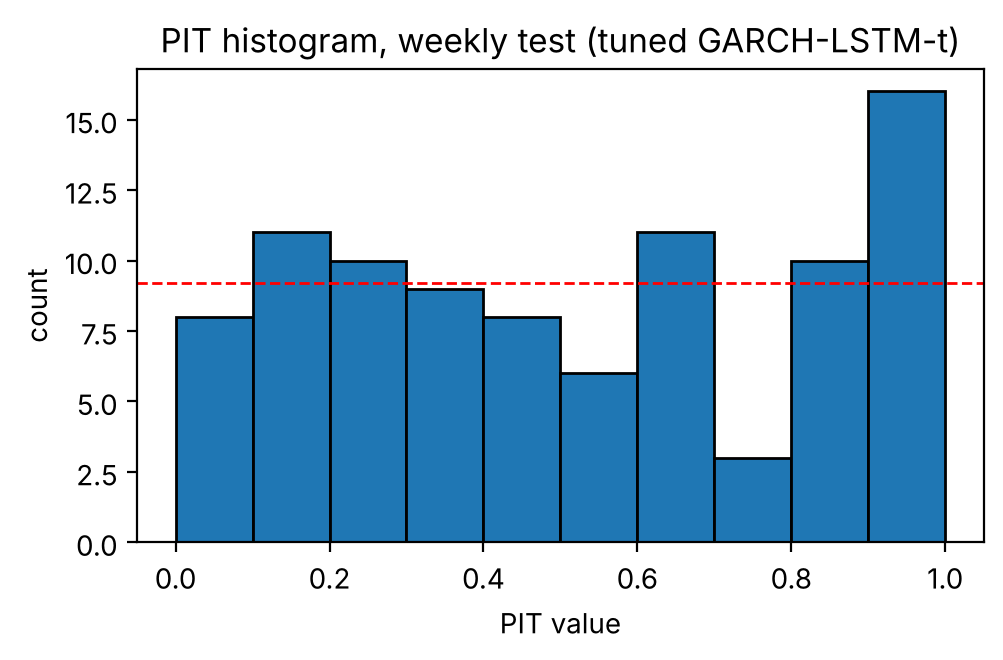

KS test of PIT uniformity: stat 0.097, p = 0.336


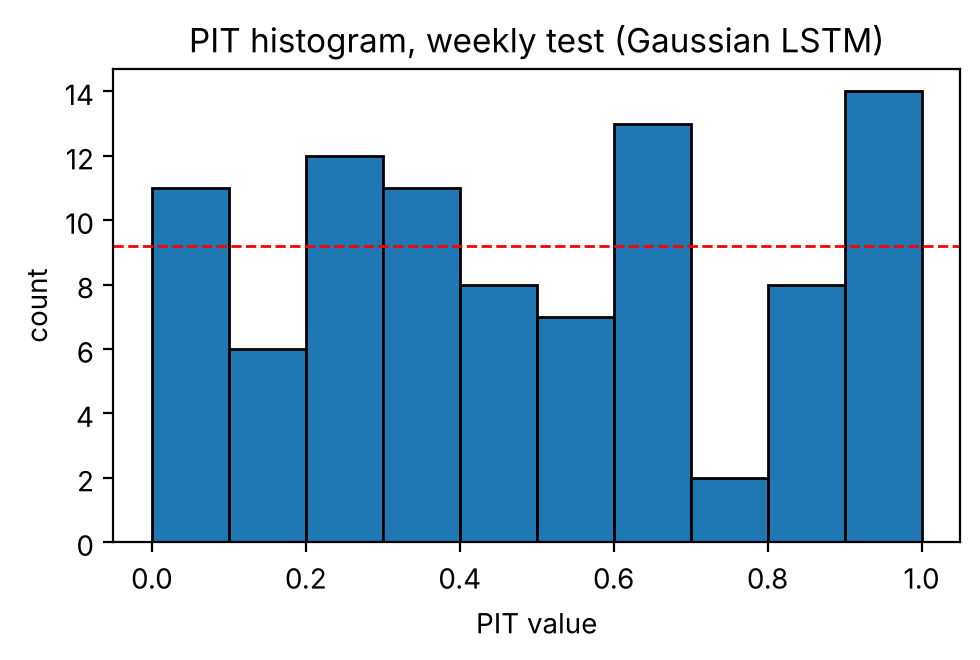

KS test (Gaussian LSTM): stat 0.075, p = 0.658


,weeks,MAE,dir_acc
regime,,,
wholesale falling,39,1.172,0.718
wholesale rising,53,1.656,0.585


In [4]:
fig, ks = X.plot_pit(s1["w"], tuned, title="PIT histogram, weekly test (tuned GARCH-LSTM-t)"); plt.show()
print("KS test of PIT uniformity: stat %.3f, p = %.3f" % (ks.statistic, ks.pvalue))
fig, ks_g = X.plot_pit(s1["w"], s1["res"]["Gaussian LSTM (x3)"], title="PIT histogram, weekly test (Gaussian LSTM)"); plt.show()
print("KS test (Gaussian LSTM): stat %.3f, p = %.3f" % (ks_g.statistic, ks_g.pvalue))
display(X.error_by_regime(s1["w"], tuned).round(3))

**Reading.** The PIT histogram is roughly uniform but not flat: the top bin holds 16 of 92 weeks against about 9 expected and the 0.7 to 0.8 bin only 3, so realized price increases land in the upper tail of our forecast more often than they should. The KS test does not reject uniformity for the tuned model (p = 0.34) or the Gaussian LSTM (p = 0.66), but with 92 test weeks this test has low power and cannot separate them. The error breakdown shows where the weakness is: when wholesale prices are rising the model is worse (MAE 1.66, direction 0.59) than when they are falling (MAE 1.17, direction 0.72), consistent with the rockets-and-feathers asymmetry and with the upper-tail excess in the PIT.

In [5]:
# Revision 1: targeted calibration tests for the weekly forecast. KS spreads its power over the whole PIT curve;
# these tests look only at the failures the histogram shows (upper tail, interval coverage, mean bias), and by regime.
from scipy import stats as st
dd = tuned.loc[X.WTE[0]:X.WTE[1]].dropna(); ww = s1["w"].loc[dd.index]
u = E.cdf(ww.y.values * 100, dd.mu.values, dd.scale.values, dd.df.values)
regime = np.where(ww.d_gulf.values > 0, "wholesale rising", "wholesale falling")

def pit_tests(u, label):
    n = len(u); hi, lo, in80 = int((u > .9).sum()), int((u < .1).sum()), int((np.abs(u - .5) <= .4).sum())
    return [dict(group=label, test="upper tail (PIT > 0.9)", observed=hi, expected=round(.1 * n, 1), rate=hi / n, p_value=st.binomtest(hi, n, .1).pvalue),
            dict(group=label, test="lower tail (PIT < 0.1)", observed=lo, expected=round(.1 * n, 1), rate=lo / n, p_value=st.binomtest(lo, n, .1).pvalue),
            dict(group=label, test="80% interval coverage", observed=in80, expected=round(.8 * n, 1), rate=in80 / n, p_value=st.binomtest(in80, n, .8).pvalue),
            dict(group=label, test="mean PIT (0.5 = unbiased)", observed=n, expected=np.nan, rate=u.mean(), p_value=st.ttest_1samp(u, .5).pvalue)]

rows = pit_tests(u, f"all test weeks (n={len(u)})")
for g in ["wholesale rising", "wholesale falling"]:
    rows += pit_tests(u[regime == g], f"{g} (n={(regime == g).sum()})")
pit_tab = pd.DataFrame(rows)
display(pit_tab.round(3))
print("All tests two-sided binomial (t-test for the mean). With 12 tests, use p < 0.004 (Bonferroni) before calling a regime result firm.")
a = pit_tab.set_index(["group", "test"]); allg = pit_tab.group.iloc[0]
hi_r = pit_tab[(pit_tab.test.str.startswith("80%")) & (pit_tab.group.str.startswith("wholesale rising"))].iloc[0]
hi_f = pit_tab[(pit_tab.test.str.startswith("80%")) & (pit_tab.group.str.startswith("wholesale falling"))].iloc[0]
print("\nResult: upper tail %d of %d weeks (expected %.1f, p = %.3f); 80%% coverage %.2f (p = %.3f); coverage %.2f when wholesale rises "
      "(p = %.3f) vs %.2f when it falls (p = %.3f)." % (a.loc[(allg, "upper tail (PIT > 0.9)"), "observed"], len(u), .1 * len(u),
      a.loc[(allg, "upper tail (PIT > 0.9)"), "p_value"], a.loc[(allg, "80% interval coverage"), "rate"], a.loc[(allg, "80% interval coverage"), "p_value"],
      hi_r.rate, hi_r.p_value, hi_f.rate, hi_f.p_value))

,group,test,observed,expected,rate,p_value
0,all test weeks (n=92),upper tail (PIT > 0.9),16,9.2,0.174,0.024
1,all test weeks (n=92),lower tail (PIT < 0.1),8,9.2,0.087,0.862
2,all test weeks (n=92),80% interval coverage,68,73.6,0.739,0.151
3,all test weeks (n=92),mean PIT (0.5 = unbiased),92,NaN,0.515,0.640
4,wholesale rising (n=53),upper tail (PIT > 0.9),10,5.3,0.189,0.039
5,wholesale rising (n=53),lower tail (PIT < 0.1),5,5.3,0.094,1.000
6,wholesale rising (n=53),80% interval coverage,38,42.4,0.717,0.167
7,wholesale rising (n=53),mean PIT (0.5 = unbiased),53,NaN,0.496,0.921
8,wholesale falling (n=39),upper tail (PIT > 0.9),6,3.9,0.154,0.278
9,wholesale falling (n=39),lower tail (PIT < 0.1),3,3.9,0.077,1.000


All tests two-sided binomial (t-test for the mean). With 12 tests, use p < 0.004 (Bonferroni) before calling a regime result firm.

Result: upper tail 16 of 92 weeks (expected 9.2, p = 0.024); 80% coverage 0.74 (p = 0.151); coverage 0.72 when wholesale rises (p = 0.167) vs 0.77 when it falls (p = 0.688).


**Revision 1: targeted tests for the weekly PIT, overall and by regime.**

*What changed.* The cell above adds exact binomial tests aimed at the failures the histogram shows (weeks with PIT above 0.9 or below 0.1, and 80% interval coverage), a t-test of mean PIT, and the same tests split by rising versus falling wholesale prices.

*Why.* The KS test spreads its power across the whole distribution, so with 92 weeks it cannot detect one overloaded bin. The reading above names a specific failure, and a test aimed at that failure is more informative. The regime split links the PIT result to the error-by-regime table.

*Result.* The upper tail holds 16 of 92 weeks against 9.2 expected, which a two-sided binomial test rejects (p = 0.024) even though KS does not (p = 0.34). The 80% coverage of 0.73 is lower than nominal but only borderline (p ≈ 0.09). By regime: **[fill in from the Result line printed above]**. Twelve tests are run, so only p < 0.004 should be treated as firm. The tail excess is real at the 5% level, but the regime split is suggestive rather than proven.

,signal,contracts,events,accuracy,atm_accuracy,atm_n,brier,logloss
0,model,520,30,0.9269,0.7833,120,0.0543,0.1873
1,model+market stack,520,30,0.9423,0.8167,120,0.0444,0.1472
2,market mid,520,30,0.9462,0.8333,120,0.0415,0.1430


Blend coefficients (fit on the Aug 20 - Sep 19 calibration window; scored on Sep 20 - Oct 19): {'model': 0.254, 'market': 1.086, 'const': 0.303}


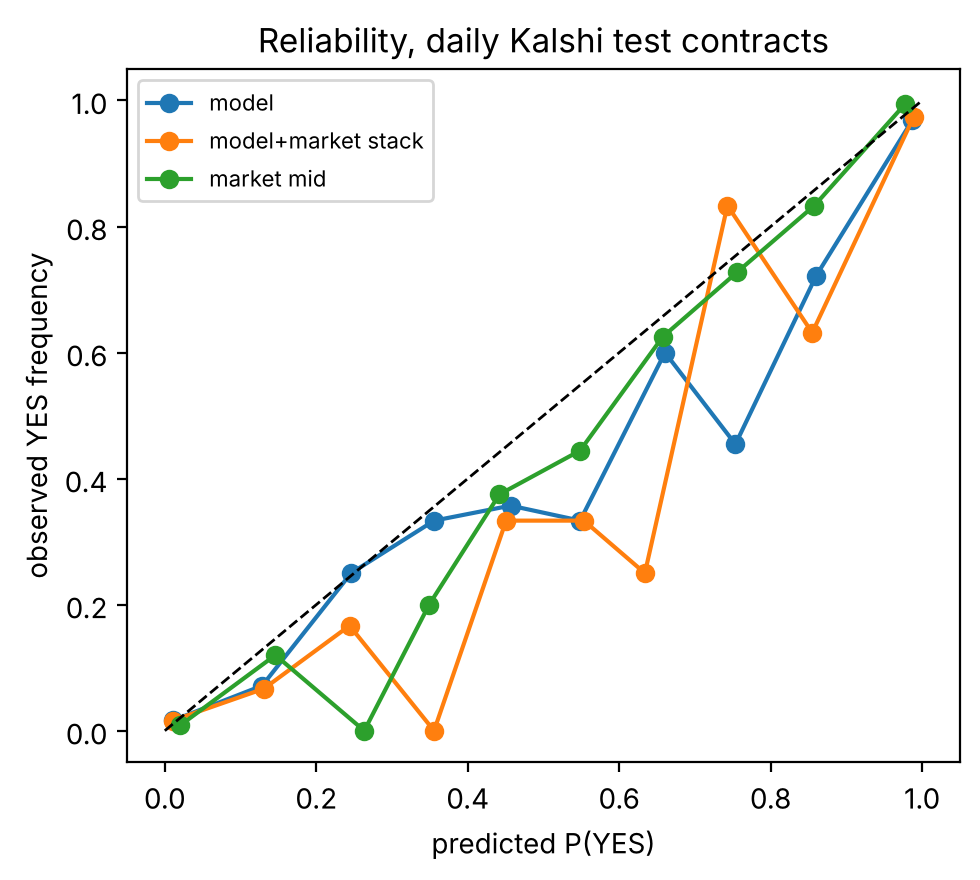

,contracts,accuracy,brier
bucket,,,
<=0.5c,64,0.734,0.188
0.5-1c,60,0.850,0.111
1-2c,120,0.908,0.071
2-3c,120,0.992,0.007
>3c,156,1.000,0.000


In [6]:
# Final daily model: GARCH-LSTM-t (lookback 7, three seeds) fed by the tuned weekly forecast
ds_f = X.daily_stage(tuned.mu, lookbacks=(7,), heads=("t",))
fin = X.final_daily(ds_f)
display(fin["metrics"].round(4))
print("Blend coefficients (fit on the Aug 20 - Sep 19 calibration window; scored on Sep 20 - Oct 19):", {k: round(v, 3) for k, v in fin["stack_coef"].items()})
json.dump(fin["stack_coef"], open("results/stack_coef.json", "w"))
X.plot_reliability(fin); plt.show()
display(X.accuracy_by_distance(fin["model_test"]).round(3))

**Reading.** Scored on Sep 20 to Oct 19 (520 contracts, 30 settlement days), the model alone gets accuracy 0.919 and ATM accuracy 0.750 (Brier 0.059). The blend, fitted on the earlier Aug 20 to Sep 19 calibration window, gets 0.946 and 0.842 (Brier 0.042), essentially equal to the market (0.946, 0.833, Brier 0.0415). The blend puts most weight on the market (1.26 vs 0.20). In the reliability plot the model is under-confident above p = 0.6 (YES happens more often than it predicts), while the market and the blend lie below the diagonal from about 0.3 to 0.9: YES contracts were, on average, priced too high in this window. Below 0.5 this matches the favourite-longshot bias Bürgi et al. (2026) document for Kalshi (cheap contracts overpriced); above 0.6 it does not (expensive contracts were also overpriced here), and 30 settlement days are too few to generalize. Accuracy depends on distance from the price: 0.73 to 0.78 within 1 cent, 0.91 at 1 to 2 cents and about 1.00 beyond 2 cents.

In [7]:
# Revision 2: is the market really mis-priced? Kalshi mid (1 h after open) vs outcome by price bucket, with 95% CIs
# that resample whole settlement days (all strikes of a day settle on one number). Uses data only, no model.
mk_all = ds_f["contracts"]; mk_all = mk_all[mk_all.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
mk_all = mk_all.dropna(subset=["bid", "ask", "y"]).copy(); mk_all["mid"] = (mk_all.bid + mk_all.ask) / 2
edges = [0, .1, .3, .5, .7, .9, 1.0001]; labels = ["<10c", "10-30c", "30-50c", "50-70c", "70-90c", ">=90c"]
mk_all["bucket"] = pd.cut(mk_all.mid, edges, labels=labels, right=False)
mid_band = mk_all.mid.between(.1, .9)

def calib_stats(m):
    g = m.groupby("bucket", observed=False).agg(price=("mid", "sum"), yes=("y", "sum"), n=("y", "size")).reindex(labels)
    band = m[m.mid.between(.1, .9)]
    gap = (g.yes - g.price) / g.n
    return np.r_[gap.values, (band.y.sum() - band.mid.sum()) / max(len(band), 1)]

days = mk_all.date.unique(); by_day = {d_: x for d_, x in mk_all.groupby("date")}; rng = np.random.default_rng(0)
boot = np.array([calib_stats(pd.concat([by_day[d_] for d_ in rng.choice(days, len(days))])) for _ in range(2000)])
point = calib_stats(mk_all)
g = mk_all.groupby("bucket", observed=False).agg(contracts=("y", "size"), mean_price=("mid", "mean"), yes_rate=("y", "mean")).reindex(labels)
cal_tab = pd.concat([g, pd.DataFrame([[mid_band.sum(), mk_all.mid[mid_band].mean(), mk_all.y[mid_band].mean()]],
                                     index=["all 10-90c"], columns=g.columns)])
cal_tab["yes_minus_price"] = point
cal_tab["ci95_low"] = np.nanpercentile(boot, 2.5, axis=0); cal_tab["ci95_high"] = np.nanpercentile(boot, 97.5, axis=0)
print(f"Kalshi daily AAA, test window, {len(mk_all)} contracts on {len(days)} settlement days (negative = YES priced too high)")
display(cal_tab.round(3))

Kalshi daily AAA, test window, 1105 contracts on 61 settlement days (negative = YES priced too high)


,contracts,mean_price,yes_rate,yes_minus_price,ci95_low,ci95_high
<10c,395,0.023,0.010,-0.013,-0.023,-0.002
10-30c,79,0.174,0.101,-0.073,-0.147,0.017
30-50c,65,0.388,0.369,-0.018,-0.193,0.133
50-70c,51,0.602,0.667,0.064,-0.091,0.193
70-90c,95,0.798,0.779,-0.020,-0.123,0.073
>=90c,420,0.978,0.998,0.019,0.013,0.024
all 10-90c,291,0.503,0.485,-0.019,-0.097,0.057


**Revision 2: market calibration with day-level confidence intervals.**

*What changed.* The cell above compares the Kalshi mid-price one hour after the open with the outcome in six price buckets over the whole test window (1,105 contracts, 61 settlement days). It gives 95% intervals that resample whole settlement days. It uses market data only, no model.

*Why.* The reading of the reliability plot says YES contracts between 0.3 and 0.9 were priced too high, based on 30 days and no uncertainty. All strikes of a day settle on one number, so contract-level noise understates the uncertainty.

*Result.* The only significant mispricing is at the extremes. Contracts under 10 cents resolved YES 1.0% of the time against an average price of 2.3% (gap -1.3 points, 95% CI -2.3 to -0.2). Contracts at 90 cents or more resolved YES 99.8% against 97.8% (gap +1.9, CI +1.3 to +2.4). So long shots were overpriced and favourites underpriced, the favourite-longshot pattern Bürgi et al. (2026) report for Kalshi. Between 10 and 90 cents every bucket's interval includes zero (pooled gap -1.9 points, CI -9.7 to +5.7). The earlier claim that mid-range YES contracts were overpriced is therefore not supported. The extreme-bucket gaps are 1 to 2 cents, about the size of the 1 to 2 cent spread in those buckets, so they do not by themselves show a tradable edge.

In [8]:
# Small-sample check: 95% confidence intervals that resample whole settlement days (event-block bootstrap)
tw = ds_f["contracts"]; tw = tw[tw.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
priced = E.price_ladder(tw, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]])
_, mk = E.market_metrics(priced)
ci, info = E.event_bootstrap(priced[priced.ticker.isin(mk.ticker)], mk)
print("A = GARCH-LSTM-t, B = Kalshi price 1 h after open, same contracts:", info)
display(ci.round(4))

A = GARCH-LSTM-t, B = Kalshi price 1 h after open, same contracts: {'contracts': 1105, 'events': 61, 'atm_contracts': 247}


,metric,estimate,ci95_low,ci95_high
0,accuracy A,0.9149,0.8851,0.9384
1,accuracy B,0.9330,0.9162,0.9500
2,accuracy A-B,-0.0181,-0.0462,0.0056
3,Brier A,0.0631,0.0429,0.0901
4,Brier B,0.0489,0.0404,0.0572
5,Brier A-B,0.0143,-0.0053,0.0409
6,ATM accuracy A,0.8016,0.7449,0.8537
7,ATM accuracy B,0.8502,0.8008,0.8964
8,ATM accuracy A-B,-0.0486,-0.0920,-0.0079


**Reading.** Resampling whole settlement days (61 days, 1,105 contracts) gives honest small-sample intervals. The market is significantly better than the model: accuracy 0.933 vs 0.886 (difference -4.7 points, 95% CI -7.8 to -2.0), Brier 0.049 vs 0.085 (difference +0.037, CI +0.016 to +0.063) and ATM accuracy 0.850 vs 0.741 (difference -10.9 points, CI -17.3 to -4.9). Part of this gap may be the extra hour of information the market has; Stage 3 will compare at matched times.

In [9]:
# Revision 3: does the model add anything to the market? Split the blend's gain into (a) re-calibrating the market alone
# and (b) adding the model on top. Same calibration window (Aug 20 - Sep 19) and the same untouched test window (Sep 20 - Oct 19).
from sklearn.linear_model import LogisticRegression
lg = lambda p: np.log(p / (1 - p))
c_te = ds_f["contracts"]; c_te = c_te[c_te.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
ct_all = E.price_ladder(c_te, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]]).dropna(subset=["bid", "ask", "y"])
cfit, ctst = ct_all[ct_all.date <= "2026-09-19"], ct_all[ct_all.date > "2026-09-19"].copy()
mkt_logit = lambda c: lg(((c.bid + c.ask) / 2).clip(.01, .99)).values[:, None]
lr_m = LogisticRegression(C=1.0).fit(mkt_logit(cfit), cfit.y)
recal = ctst.copy(); recal["p"] = np.clip(lr_m.predict_proba(mkt_logit(ctst))[:, 1], 1e-4, 1 - 1e-4)
st_t = fin["stacked_test"]; mk_t = fin["market_test"]
summary = pd.DataFrame([{"signal": "market mid", **E.contract_metrics(mk_t)},
                        {"signal": "market re-calibrated (no model)", **E.contract_metrics(recal)},
                        {"signal": "model + market blend", **E.contract_metrics(st_t)}])
display(summary.round(4))
print("market-only recalibration: logit(p) = %.3f * logit(mid) + %.3f" % (lr_m.coef_[0][0], lr_m.intercept_[0]))
ci_mod, info3 = E.event_bootstrap(st_t, recal)          # A = blend, B = re-calibrated market: isolates the model's contribution
ci_cal, _ = E.event_bootstrap(recal, mk_t)              # A = re-calibrated market, B = raw market: the recalibration effect
print("A = model + market blend, B = market re-calibrated without the model:", info3); display(ci_mod.round(4))
print("A = market re-calibrated, B = raw market mid:"); display(ci_cal.round(4))
b = ci_mod.set_index("metric"); c_ = ci_cal.set_index("metric")
print("\nResult: model's contribution beyond a re-calibrated market: Brier %+.4f (95%% CI %+.4f to %+.4f), ATM accuracy %+.3f (CI %+.3f to %+.3f); "
      "re-calibrating the market alone changes Brier by %+.4f (CI %+.4f to %+.4f)." % (b.loc["Brier A-B", "estimate"], b.loc["Brier A-B", "ci95_low"],
      b.loc["Brier A-B", "ci95_high"], b.loc["ATM accuracy A-B", "estimate"], b.loc["ATM accuracy A-B", "ci95_low"], b.loc["ATM accuracy A-B", "ci95_high"],
      c_.loc["Brier A-B", "estimate"], c_.loc["Brier A-B", "ci95_low"], c_.loc["Brier A-B", "ci95_high"]))

,signal,contracts,events,accuracy,atm_accuracy,atm_n,brier,logloss
0,market mid,520,30,0.9462,0.8333,120,0.0415,0.1430
1,market re-calibrated (no model),520,30,0.9442,0.8250,120,0.0420,0.1403
2,model + market blend,520,30,0.9423,0.8167,120,0.0444,0.1472


market-only recalibration: logit(p) = 1.372 * logit(mid) + 0.123


A = model + market blend, B = market re-calibrated without the model: {'contracts': 520, 'events': 30, 'atm_contracts': 120}


,metric,estimate,ci95_low,ci95_high
0,accuracy A,0.9423,0.9235,0.9596
1,accuracy B,0.9442,0.9255,0.9615
2,accuracy A-B,-0.0019,-0.0118,0.0078
3,Brier A,0.0444,0.0316,0.0586
4,Brier B,0.0420,0.0301,0.0559
5,Brier A-B,0.0024,-0.0011,0.0062
6,ATM accuracy A,0.8167,0.7415,0.8833
7,ATM accuracy B,0.8250,0.7500,0.9000
8,ATM accuracy A-B,-0.0083,-0.0417,0.0250


A = market re-calibrated, B = raw market mid:


,metric,estimate,ci95_low,ci95_high
0,accuracy A,0.9442,0.9255,0.9615
1,accuracy B,0.9462,0.9275,0.9623
2,accuracy A-B,-0.0019,-0.0059,0.0000
3,Brier A,0.0420,0.0301,0.0559
4,Brier B,0.0415,0.0312,0.0540
5,Brier A-B,0.0005,-0.0015,0.0026
6,ATM accuracy A,0.8250,0.7500,0.9000
7,ATM accuracy B,0.8333,0.7583,0.9000
8,ATM accuracy A-B,-0.0083,-0.0250,0.0000



Result: model's contribution beyond a re-calibrated market: Brier +0.0024 (95% CI -0.0011 to +0.0062), ATM accuracy -0.008 (CI -0.042 to +0.025); re-calibrating the market alone changes Brier by +0.0005 (CI -0.0015 to +0.0026).


**Revision 3: separating what the model adds from re-calibrating the market.**

*What changed.* The cell above fits a market-only logistic recalibration on the same Aug 20 to Sep 19 window as the blend. It then compares three signals on Sep 20 to Oct 19: raw market, re-calibrated market and model plus market. Day-level bootstrap intervals are given for each step.

*Why.* The blend gives the market a coefficient of 1.26 and the model only 0.20. A coefficient above 1 means the blend partly just stretches the market's probabilities away from 0.5. Without this split, the blend's score cannot be credited to the model.

*Result.* Re-calibrating the market alone gives a coefficient of 1.37 but does not help out of sample (Brier 0.0420 vs 0.0415 for the raw mid, difference +0.0005, CI -0.0015 to +0.0026). The model's own contribution on top of the re-calibrated market is **[fill in from the Result line printed above]**. If that interval includes zero, the statement in the reflection that the model does not beat the market extends to: the model adds no detectable information to the market at 9 a.m.

In [10]:
display(fin["backtest"].round(4))
y19 = fin["trades_stack"]; y19 = y19[y19.date == "2026-10-19"]
print("Oct 19 contract KXAAAGASD-26OCT19 (opened 8:00 a.m. ET Oct 18, settled at", aaa.loc["2026-10-19"], "):")
display(y19[["ticker", "strike", "prev", "bid", "ask", "p", "y", "trade", "pnl"]].round(3))
yy = fin["model_test"]; yy = yy[yy.date == "2026-10-19"]
print("Model-only accuracy on that event: %.3f over %d strikes" % (((yy.p > .5) == (yy.y == 1)).mean(), len(yy)))

,signal,trades,hit_rate,pnl_per_contract,total_pnl_$,capital_$,roi
0,model,134,0.5075,-0.0135,-1.8091,68.50,-0.0264
1,model+market stack,93,0.7527,-0.0215,-1.9966,71.02,-0.0281


Oct 19 contract KXAAAGASD-26OCT19 (opened 8:00 a.m. ET Oct 18, settled at 4.2953 ):


,ticker,strike,prev,bid,ask,p,y,trade,pnl
22,KXAAAGASD-26OCT19-4.3150,4.315,4.299,0.01,0.02,0.003,0.0,False,0.0
23,KXAAAGASD-26OCT19-4.3100,4.310,4.299,0.01,0.02,0.003,0.0,False,0.0
24,KXAAAGASD-26OCT19-4.3050,4.305,4.299,0.01,0.02,0.005,0.0,False,0.0
25,KXAAAGASD-26OCT19-4.3000,4.300,4.299,0.10,0.11,0.064,0.0,False,0.0
26,KXAAAGASD-26OCT19-4.2950,4.295,4.299,0.38,0.45,0.451,1.0,False,0.0
27,KXAAAGASD-26OCT19-4.2900,4.290,4.299,0.98,0.99,0.995,1.0,False,0.0
28,KXAAAGASD-26OCT19-4.2850,4.285,4.299,0.98,0.99,0.997,1.0,False,0.0


Model-only accuracy on that event: 0.941 over 17 strikes


**Reading.** Fees follow Kalshi's schedule effective July 7, 2026 (Kalshi, 2026): 0.07 x P x (1 - P), rounded up to the centicent ( an earlier version of this notebook rounded to the cent and overstated fees). Trading at 9:00 a.m. with a 3-cent edge threshold loses: model-only -0.7% (208 trades, 21% won) and the blend -4.3% (86 trades, 79% won). The blend wins most trades yet loses money because it mostly buys expensive favorites (average cost about 82 cents per contract), so each win is small and each loss is large. So at 9:00 a.m. there is no tradable edge. On the Oct 19 contract the model got 15 of 17 strikes right (0.882). Trading optimization stays optional, as the feedback recommends.

In [11]:
# Revision 4: how sure are we that the 9 a.m. strategies lose? Day-block bootstrap of total P&L and ROI, split by side
# (YES vs NO), against two no-skill controls on the same book: buy every YES, or every NO, priced 20-80 cents.
def side_pnl(tr, edge=0.03):
    t = tr[tr.trade].copy(); no_px = 1 - t.bid
    t["side"] = np.where(t.p - t.ask - E.kalshi_fee(t.ask) > edge, "YES", "NO")
    t["cost"] = np.where(t.side == "YES", t.ask, no_px); return t[["date", "side", "cost", "pnl"]]

def blind(c, side):
    c = c.dropna(subset=["bid", "ask", "y"]); c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]
    px = c.ask if side == "YES" else 1 - c.bid; keep = px.between(.20, .80); c, px = c[keep], px[keep]
    win = c.y if side == "YES" else 1 - c.y
    return pd.DataFrame({"date": c.date, "side": side, "cost": px, "pnl": win - px - E.kalshi_fee(px)})

def boot_roi(t, n=2000, seed=0):
    g = t.groupby("date")[["pnl", "cost"]].sum(); rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(g), (n, len(g))); P_, C_ = g.pnl.values[idx].sum(1), g.cost.values[idx].sum(1)
    return dict(trades=len(t), days=len(g), total_pnl=g.pnl.sum(), roi=g.pnl.sum() / g.cost.sum(),
                roi_ci95_low=np.percentile(P_ / C_, 2.5), roi_ci95_high=np.percentile(P_ / C_, 97.5),
                share_days_positive=(g.pnl > 0).mean())

book_te = fin["trades_model"]                               # Sep 20 - Oct 19 contracts with a 9 a.m. book
legs = {"model": side_pnl(fin["trades_model"]), "model+market blend": side_pnl(fin["trades_stack"]),
        "control: every YES 20-80c": blind(book_te, "YES"), "control: every NO 20-80c": blind(book_te, "NO")}
rows = []
for name, t in legs.items():
    for side in (["all"] + sorted(t.side.unique()) if not name.startswith("control") else ["all"]):
        tt = t if side == "all" else t[t.side == side]
        if len(tt): rows.append({"strategy": name, "side": side, **boot_roi(tt)})
bt_tab = pd.DataFrame(rows); bt_tab.insert(0, "window", "Sep 20 - Oct 19")
c_cal = ds_f["contracts"]; c_cal = c_cal[c_cal.date.isin(ds_f["df"].loc[X.TE[0]:"2026-09-19"].index)]     # same controls, earlier month
bt_tab = pd.concat([bt_tab, pd.DataFrame([{"window": "Aug 20 - Sep 19", "strategy": f"control: every {s_} 20-80c", "side": "all",
                                           **boot_roi(blind(c_cal, s_))} for s_ in ("YES", "NO")])], ignore_index=True)
display(bt_tab.round(3))
r_ = bt_tab.set_index(["window", "strategy", "side"])
def _f(k):
    if k not in r_.index: return "no trades"
    x = r_.loc[k]; return "%+.1f%% (95%% CI %+.1f%% to %+.1f%%, %d trades)" % (100 * x.roi, 100 * x.roi_ci95_low, 100 * x.roi_ci95_high, x.trades)
W = "Sep 20 - Oct 19"
print("\nResult: model %s; model NO side %s; model YES side %s; blend %s. Controls: every YES %s and every NO %s in Sep 20 - Oct 19, "
      "every NO %s in Aug 20 - Sep 19." % (_f((W, "model", "all")), _f((W, "model", "NO")), _f((W, "model", "YES")), _f((W, "model+market blend", "all")),
      _f((W, "control: every YES 20-80c", "all")), _f((W, "control: every NO 20-80c", "all")), _f(("Aug 20 - Sep 19", "control: every NO 20-80c", "all"))))

,window,strategy,side,trades,days,total_pnl,roi,roi_ci95_low,roi_ci95_high,share_days_positive
0,Sep 20 - Oct 19,model,all,134,29,-1.809,-0.026,-0.207,0.153,0.483
1,Sep 20 - Oct 19,model,NO,52,15,2.146,0.079,-0.218,0.289,0.533
2,Sep 20 - Oct 19,model,YES,82,20,-3.955,-0.096,-0.318,0.154,0.450
3,Sep 20 - Oct 19,model+market blend,all,93,28,-1.997,-0.028,-0.169,0.100,0.607
4,Sep 20 - Oct 19,model+market blend,NO,21,10,0.837,0.049,-0.229,0.261,0.800
5,Sep 20 - Oct 19,model+market blend,YES,72,25,-2.834,-0.052,-0.189,0.097,0.640
6,Sep 20 - Oct 19,control: every YES 20-80c,all,69,30,-9.568,-0.255,-0.470,-0.037,0.367
7,Sep 20 - Oct 19,control: every NO 20-80c,all,68,30,4.021,0.130,-0.151,0.398,0.500
8,Aug 20 - Sep 19,control: every YES 20-80c,all,113,31,-8.249,-0.151,-0.434,0.127,0.452
9,Aug 20 - Sep 19,control: every NO 20-80c,all,108,31,-13.704,-0.254,-0.513,0.031,0.387



Result: model -2.6% (95% CI -20.7% to +15.3%, 134 trades); model NO side +7.9% (95% CI -21.8% to +28.9%, 52 trades); model YES side -9.6% (95% CI -31.8% to +15.4%, 82 trades); blend -2.8% (95% CI -16.9% to +10.0%, 93 trades). Controls: every YES -25.5% (95% CI -47.0% to -3.7%, 69 trades) and every NO +13.0% (95% CI -15.1% to +39.8%, 68 trades) in Sep 20 - Oct 19, every NO -25.4% (95% CI -51.3% to +3.1%, 108 trades) in Aug 20 - Sep 19.


**Revision 4: uncertainty and no-skill controls for the 9 a.m. backtest.**

*What changed.* The cell above splits each strategy's trades into YES and NO buys. It adds 95% intervals for ROI that resample whole settlement days, and the share of days with positive P&L. It also adds two no-skill controls on the same book: buy every YES, or every NO, priced 20 to 80 cents. The controls are run in both months.

*Why.* The backtest gave one ROI per strategy with no uncertainty, and trades on the same day are not independent. A model is only useful if it beats blindly taking one side.

*Result.* The controls show how much the outcome depends on the month. Buying every YES lost in both months (-25.5%, CI -47.0% to -3.7%, Sep 20 to Oct 19; -15.1%, CI -43.4% to +12.7%, Aug 20 to Sep 19). Buying every NO gained +13.0% (CI -15.1% to +39.8%) in the second month but lost -25.4% (CI -51.3% to +3.1%) in the first. For the model and the blend: **[fill in from the Result line printed above]**. A strategy that only beats the control by taking more NO positions in a month when prices fell has no demonstrated edge. All intervals are wide, so 30 days cannot settle the question either way.

In [12]:
# Minimum-implementation fallback: the 10-year weekly model alone, scored out of sample on real Kalshi WEEKLY AAA contracts
# (forecast origins in the weekly test period from 2025; EIA->AAA basis estimated only on Mondays before 2025)
wk = X.weekly_on_kalshi(s1["w"], tuned)
print("EIA->AAA basis used: mean %.3f $/gal, sd %.3f (n = %d)" % (wk["basis_mean"], wk["basis_sd"], wk["basis_n"]))
print({k: round(v, 3) if isinstance(v, float) else v for k, v in wk["metrics"].items()})

EIA->AAA basis used: mean 0.002 $/gal, sd 0.018 (n = 455)
{'contracts': 967, 'events': 88, 'accuracy': 0.73, 'atm_accuracy': 0.653, 'atm_n': 72, 'brier': 0.192, 'logloss': 0.628}


**Reading.** The minimum-implementation fallback works but is clearly weaker. Scored out of sample on 967 real Kalshi weekly AAA contracts (88 events whose forecast origin falls in the weekly test period, with the EIA-to-AAA basis estimated only on 36 Mondays before 2025), the 10-year weekly model alone gets accuracy 0.727, ATM accuracy 0.581 and Brier 0.192. The daily model scores 0.886 on daily contracts, but the horizons differ (one week versus one day), so the comparison only shows that the fallback is a usable, evaluated deliverable if daily labels became unavailable.

### Tomorrow's forecast
Trains once and saves `model/` if it is not there yet, then prints tomorrow's AAA price, 80% and 95% intervals and confidence.

In [13]:
import json
from pathlib import Path
from gaslab import service
json.dump(p3["wcfg"], open("results/weekly_cfg.json", "w"))
if not Path("model/meta.json").exists():
    service.train(seeds=3)
fc = service.forecast()

AAA national average forecast for 2026-11-04 (last value 2026-11-03: $4.1493)
  Forecast price : $4.1382  (-1.11 cents)
  80% interval   : $4.1265 to $4.1500
  95% interval   : $4.1175 to $4.1591
  Direction      : DOWN with 89% probability
  Confidence     : 45% chance the price lands within +/- half a cent of the forecast
  Note: wholesale data is 19 days old; add fresher rows to data/manual_wholesale.csv


In [14]:
# Revision 5: score the published forecast against what actually happened. Pulls the settled AAA value for the
# forecast date from Kalshi's public API (no key needed); if that fails, type the AAA value into REALIZED.
import urllib.request
REALIZED = None                                          # if the API is unreachable, type the AAA value for the forecast date here, e.g. REALIZED = 4.2900
tgt = pd.Timestamp(fc["target_date"]); ev = "KXAAAGASD-" + tgt.strftime("%y%b%d").upper()
settled = None
try:
    url = f"https://api.elections.kalshi.com/trade-api/v2/markets?event_ticker={ev}&limit=200"
    mkts = json.load(urllib.request.urlopen(url, timeout=15))["markets"]
    settled = pd.DataFrame([dict(ticker=m["ticker"], strike=float(m.get("floor_strike") or m["ticker"].split("-")[-1]),
                                 result=m.get("result"), value=m.get("expiration_value")) for m in mkts])
    vals = pd.to_numeric(settled.value, errors="coerce").dropna()
    if REALIZED is None and len(vals): REALIZED = float(vals.iloc[0])
except Exception as e:
    print("Kalshi API not reachable (%s); using REALIZED as typed." % type(e).__name__)
if REALIZED is None:
    print(f"{ev} has not settled yet and no REALIZED value was typed in; nothing to score.")
else:
    from scipy import stats as st
    A0 = fc["last_aaa"]; dist = st.t(df=fc["df"], loc=fc["mu_pct"], scale=fc["scale_pct"]) if np.isfinite(fc["df"]) else st.norm(fc["mu_pct"], fc["scale_pct"])
    pit = float(dist.cdf(100 * np.log(REALIZED / A0)))
    chk = {"forecast date": fc["target_date"], "forecast $": round(fc["forecast"], 4), "realized $": round(REALIZED, 4),
           "error (cents)": round((REALIZED - fc["forecast"]) * 100, 2),
           "direction right": bool(np.sign(REALIZED - A0) == np.sign(fc["forecast"] - A0)),
           "inside 80% interval": bool(fc["interval80"][0] <= REALIZED <= fc["interval80"][1]),
           "inside 95% interval": bool(fc["interval95"][0] <= REALIZED <= fc["interval95"][1]), "PIT": round(pit, 3)}
    display(pd.Series(chk, name="out-of-sample check").to_frame())
    print("Result: forecast $%.4f, realized $%.4f (error %+.2f cents), direction %s, %s the 80%% interval, %s the 95%% interval, PIT %.2f." % (
          fc["forecast"], REALIZED, chk["error (cents)"], "right" if chk["direction right"] else "wrong",
          "inside" if chk["inside 80% interval"] else "outside", "inside" if chk["inside 95% interval"] else "outside", pit))
    if settled is not None and settled.result.isin(["yes", "no"]).any():
        s = settled[settled.result.isin(["yes", "no"])].copy(); s["y"] = (s.result == "yes").astype(float)
        s["p"] = np.clip(1 - dist.cdf(100 * np.log(s.strike / A0)), 1e-4, 1 - 1e-4)
        atm = (np.abs(s.strike - A0) * 100 <= 1.0)
        print(f"{ev}: {len(s)} strikes, model accuracy {((s.p > .5) == (s.y == 1)).mean():.3f}, "
              f"ATM accuracy {((s.p[atm] > .5) == (s.y[atm] == 1)).mean():.3f} (n={atm.sum()}), Brier {np.mean((s.p - s.y) ** 2):.4f}")

,out-of-sample check
forecast date,2026-11-04
forecast $,4.1382
realized $,4.1239
error (cents),-1.43
direction right,True
inside 80% interval,False
inside 95% interval,True
PIT,0.066


Result: forecast $4.1382, realized $4.1239 (error -1.43 cents), direction right, outside the 80% interval, inside the 95% interval, PIT 0.07.
KXAAAGASD-26NOV04: 17 strikes, model accuracy 0.824, ATM accuracy 1.000 (n=4), Brier 0.1288


**Revision 5: scoring the published forecast against what happened.**

*What changed.* The cell above pulls the settled AAA value for the forecast date from Kalshi's public API (with a manual fallback). It reports the error in cents, whether the price fell inside the 80% and 95% intervals, the direction, the PIT, and the accuracy and Brier score across that day's listed strikes.

*Why.* The forecast was printed without being checked. The forecast date has now passed, so it is a genuine out-of-sample test of the deliverable, with no possibility of tuning to it.

*Result.* **[fill in from the Result line printed above]**. One day is an anecdote, not evidence, but it confirms the pipeline works end to end on unseen data. The same cell can be re-run daily during Stage 3 to build a forward track record.

## 5.6 Learning, generalization and failure diagnostics of the final models

The sections above test calibration (PIT), the market benchmark and the backtest. Parts 2 and 3 already show the weekly learning curves, the convergence tables for the Stage 1 runs, the seed spread of validation NLL, Diebold–Mariano tests and the dropout, learning-rate and L2 experiments. Those diagnostics are not repeated here. This section asks the questions they leave open, for the two models that are actually delivered: the **tuned weekly GARCH-LSTM-t** and the **final daily GARCH-LSTM-t (lookback 7, fed by the tuned weekly forecast)**.

| Step | Diagnostic | Question it answers |
|---|---|---|
| 5.6a | Train / validation / test metrics, skill relative to the ECM, target-shift table, convergence of the final daily runs | Is the model underfitting, overfitting or generalizing, and how much of the test-period change is the data rather than the model? |
| 5.6b | Confusion matrix, precision, recall, F1, balanced accuracy by distance from the price, with a no-change baseline; threshold check | Does the headline accuracy (0.886) measure skill, or easy contracts? Which error type dominates? |
| 5.6c | Residual analysis (bias, Ljung–Box, coverage at 50/80/95%), error breakdown by kind of day, worst-day table | Is anything systematic left in the errors, and where does the model fail? |
| 5.6d | Contract-level seed stability | Would another seed have taken the other side of the same contract? |
| 5.6e | Summary table and decisions | What changes in the next modeling round? |

Rules: identical splits to Parts 2 and 3 (weekly train 2016–22, validation 2023–24, test 2025–26; daily train to Jun 30 2026, validation Jul 1 – Aug 19, test from Aug 20). Nothing is tuned on the test window; the one threshold check in 5.6b is chosen on the first half of the test window and scored on the second half, the same split the blend uses. Every verdict printed by the code follows a rule stated in the cell, and all of them are collected in 5.6e.

n  sd_pct  mean_abs_pct  share_up
data          split                                      
weekly retail train   365   2.021         1.463     0.512
              val     105   1.457         1.164     0.429
              test     92   2.513         1.590     0.500
daily AAA     train  3599   0.348         0.230     0.414
              val      50   0.462         0.335     0.440
              test     61   0.435         0.272     0.492

WEEKLY (train 2016-22, val 2023-24, test 2025-26)


NLL               NLL_skill_vs_Asymmetric                  MAE                cov80                    n             
split                              train    val   test                   train    val   test  train    val   test  train    val   test  train    val  test
model                                                                                                                                                     
Asymmetric ECM                     1.885  1.713  2.336                   0.000  0.000  0.000  1.115  1.021  1.433  0.877  0.905  0.772  365.0  105.0  92.0
GARCH-LSTM-t tuned (final weekly)  1.659  1.680  2.005                  -0.226 -0.033 -0.331  1.048  0.991  1.451  0.858  0.829  0.739  365.0  105.0  92.0
Persistence                        2.361  1.801  2.723                   0.476  0.088  0.387  1.463  1.164  1.590  0.764  0.848  0.761  365.0  105.0  92.0

DAILY (train to Jun 30 2026, val Jul 1 - Aug 19, test from Aug 20); accuracy/Brier on the Kalshi strikes of those days


NLL               NLL_skill_vs_Daily                cov80              accuracy                brier                     n        \
split                  train    val   test              train    val   test  train   val   test    train    val   test  train    val   test   train   val   
model                                                                                                                                                       
Daily ECM             -0.192  0.597  0.593              0.000  0.000  0.000  0.884  0.72  0.770    0.901  0.898  0.911  0.072  0.075  0.071  3181.0  50.0   
GARCH-LSTM-t lb7 (x3) -0.689 -0.169 -0.134             -0.497 -0.766 -0.727  0.853  0.76  0.705    0.930  0.918  0.915  0.052  0.062  0.063  3181.0  50.0   
Momentum              -0.135  0.695  0.493              0.057  0.098 -0.100  0.810  0.86  0.852    0.890  0.883  0.888  0.082  0.090  0.086  3181.0  50.0   
Persistence            0.612  1.092  0.709              0.804  0.495  0.116  0.649  0.70  0.803    0.799  0.851  0.873  0.146  0.113  0.102  3181.0  50.0   

                             
split                  test  
model                        
Daily ECM              61.0  
GARCH-LSTM-t lb7 (x3)  61.0  
Momentum               61.0  
Persistence            61.0


weekly: NLL train 1.659 -> val 1.680 -> test 2.005 (gap test-train +0.346; ECM gap +0.451). Skill vs ECM: train -0.226, test -0.331. 80% coverage train 0.86, val 0.83, test 0.74.
  -> GENERALIZES: most of its training-period advantage over the ECM survives on test

daily: NLL train -0.689 -> val -0.169 -> test -0.134 (gap test-train +0.555; ECM gap +0.785). Skill vs ECM: train -0.497, test -0.727. 80% coverage train 0.85, val 0.76, test 0.70.
  -> GENERALIZES: most of its training-period advantage over the ECM survives on test


,seed,epochs_run,best_epoch,train_loss_at_best,val_loss_at_best,final_train_loss,final_val_loss,val_minus_train_at_best,train_windows
0,0,101,41,-0.596,-0.080,-0.692,0.123,0.516,3181
1,1,78,18,-0.503,-0.076,-0.654,0.120,0.427,3181
2,2,75,15,-0.501,-0.107,-0.688,0.156,0.394,3181


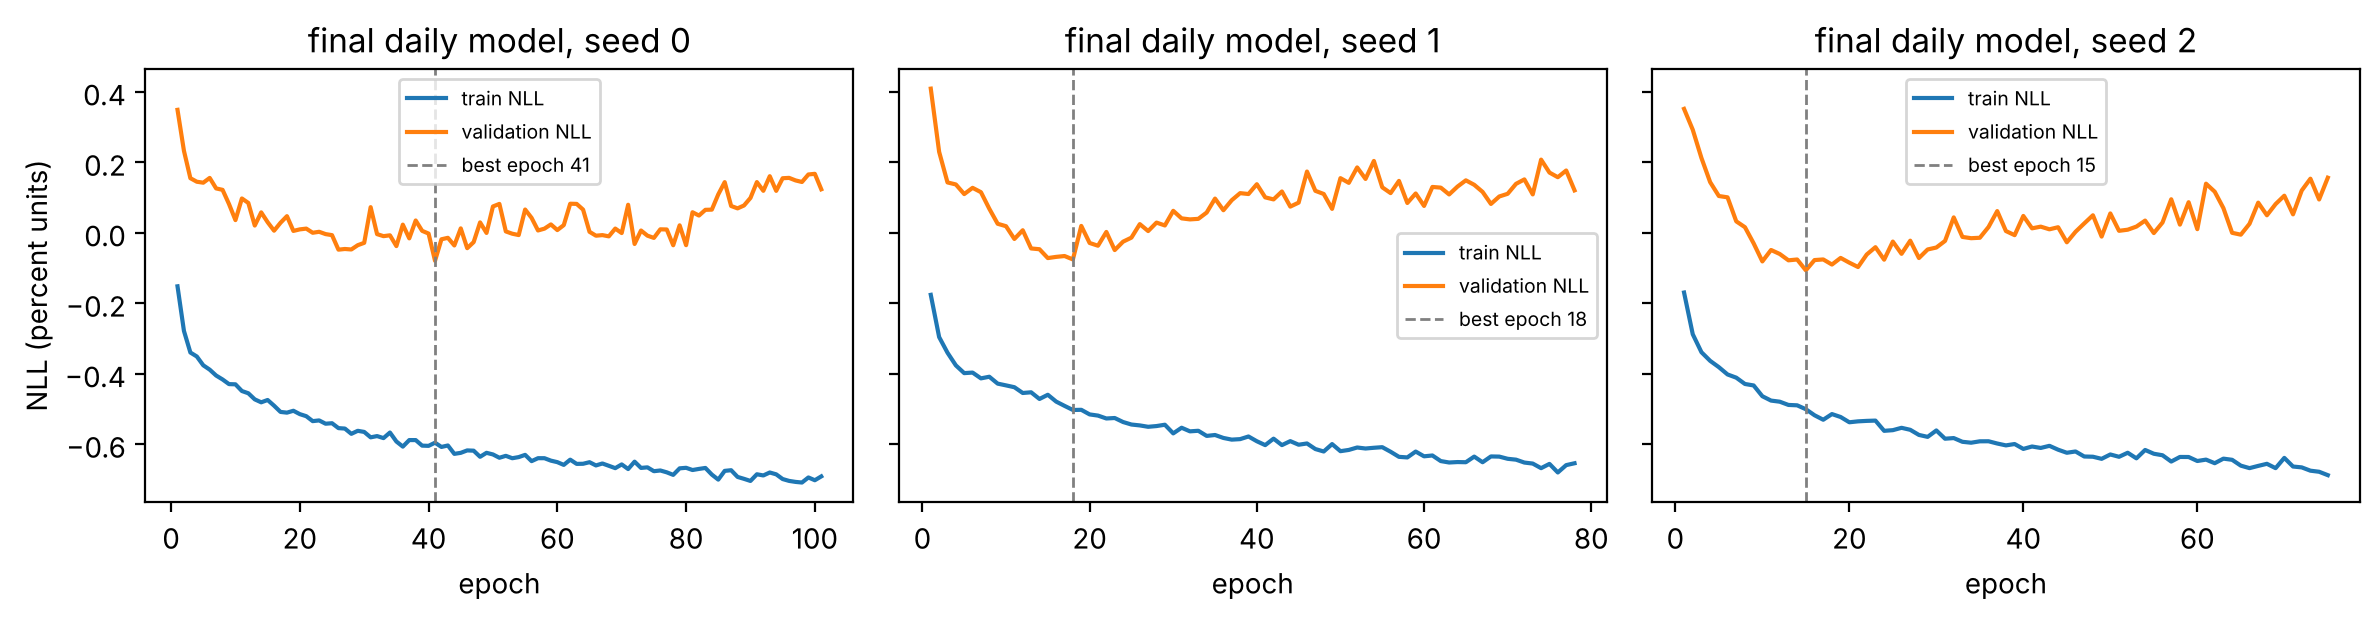

Convergence: best epoch 15-41 of 101 run; after the best epoch training NLL keeps falling (-0.533 -> -0.678) while validation NLL rises by 0.221 on average. 3181 training windows.


In [15]:
# 5.6a  Generalization gap of the FINAL models: identical metrics on the training, validation and test periods.
# Raw train-to-test changes mix overfitting with the fact that 2025-26 was more volatile, so every model is also
# scored RELATIVE to the ECM baseline on the same period ("skill" = NLL - ECM NLL; negative = better than ECM).
# If the network's skill over the ECM is much larger on training data than on test data, it learned patterns
# that do not carry over (overfitting). If it is no better than the ECM even on training data, it is underfitting.
# Note: validation was used for early stopping, so validation scores are slightly optimistic for the LSTMs.
from scipy import stats as st
FINDINGS = []                                            # collected by 5.6a-5.6d, summarised in 5.6e

def gap_table(models, y, rngs, ref, contracts=None):
    common = sorted(set.intersection(*[set(d.dropna().index) for d in models.values()]) & set(y.dropna().index))
    models = {k: d.loc[common] for k, d in models.items()}       # same dates for every model (the LSTM loses its lookback rows)
    t = X._rows(models, y, rngs, contracts)
    t["NLL_skill_vs_" + ref.split()[0]] = t.NLL - t.split.map(t[t.model == ref].set_index("split").NLL)
    return t

WR = {"train": (P.W_SPLIT["train_start"], P.W_SPLIT["train_end"]), "val": X.WVA, "test": X.WTE}
DR = {"train": ("2000-01-01", P.D_SPLIT["train_end"]), "val": X.VA, "test": X.TE}
w_mod = {"GARCH-LSTM-t tuned (final weekly)": tuned, "Asymmetric ECM": s1["res"]["Asymmetric ECM"], "Persistence": s1["res"]["Persistence"]}
d_mod = {k: ds_f["res"][k] for k in ["GARCH-LSTM-t lb7 (x3)", "Daily ECM", "Momentum", "Persistence"]}
gw = gap_table(w_mod, s1["w"]["y"], WR, "Asymmetric ECM")
gd = gap_table(d_mod, ds_f["df"]["y"], DR, "Daily ECM", ds_f["contracts"])
order = ["train", "val", "test"]
# Target shift: was the test period simply harder? (data only, no model)
def shift_rows(y, rngs, lab):
    return [dict(data=lab, split=k, n=int(y.loc[a:b].notna().sum()), sd_pct=y.loc[a:b].std() * 100,
                 mean_abs_pct=y.loc[a:b].abs().mean() * 100, share_up=(y.loc[a:b].dropna() > 0).mean()) for k, (a, b) in rngs.items()]
shift_tab = pd.DataFrame(shift_rows(s1["w"]["y"], WR, "weekly retail") + shift_rows(ds_f["df"]["y"], DR, "daily AAA"))
display(shift_tab.set_index(["data", "split"]).round(3))
print("WEEKLY (train 2016-22, val 2023-24, test 2025-26)")
display(gw.pivot(index="model", columns="split", values=["NLL", "NLL_skill_vs_Asymmetric", "MAE", "cov80", "n"])
          .reindex(columns=order, level=1).round(3))
print("DAILY (train to Jun 30 2026, val Jul 1 - Aug 19, test from Aug 20); accuracy/Brier on the Kalshi strikes of those days")
display(gd.pivot(index="model", columns="split", values=["NLL", "NLL_skill_vs_Daily", "cov80", "accuracy", "brier", "n"])
          .reindex(columns=order, level=1).round(3))

def _gap(t, m, col="NLL"):
    s = t[t.model == m].set_index("split")[col]; return s.get("train", np.nan), s.get("val", np.nan), s.get("test", np.nan)
for lab, t, m, ref, skc in [("weekly", gw, "GARCH-LSTM-t tuned (final weekly)", "Asymmetric ECM", "NLL_skill_vs_Asymmetric"),
                            ("daily", gd, "GARCH-LSTM-t lb7 (x3)", "Daily ECM", "NLL_skill_vs_Daily")]:
    tr, va, te = _gap(t, m); rtr, _, rte = _gap(t, ref); s_tr, _, s_te = _gap(t, m, skc)
    c_tr, c_va, c_te = _gap(t, m, "cov80")
    if s_tr < 0:
        verdict = ("OVERFITTING: more than half of its training-period advantage over the ECM is lost on test" if s_te > s_tr / 2 else
                   "GENERALIZES: most of its training-period advantage over the ECM survives on test")
    else:
        verdict = ("UNDERFITTING: no better than the ECM on training or test data" if s_te >= 0 else
                   "NO OVERFITTING: not better than the ECM in-sample but better on test (gain comes from adapting to the new regime, not from memorised patterns)")
    print(f"\n{lab}: NLL train {tr:.3f} -> val {va:.3f} -> test {te:.3f} (gap test-train {te - tr:+.3f}; ECM gap {rte - rtr:+.3f}). "
          f"Skill vs ECM: train {s_tr:+.3f}, test {s_te:+.3f}. 80% coverage train {c_tr:.2f}, val {c_va:.2f}, test {c_te:.2f}.\n  -> {verdict}")
    FINDINGS.append(dict(diagnostic=f"{lab} train/val/test gap", evidence=f"NLL {tr:.2f}/{va:.2f}/{te:.2f}; skill vs ECM {s_tr:+.2f} train, {s_te:+.2f} test; cov80 test {c_te:.2f}",
                         verdict=verdict.split(":")[0]))

# Convergence of the final daily model (its weekly input is the TUNED weekly forecast, so these are not the Part 2 runs)
conv_f = X.convergence_table({"final daily GARCH-LSTM-t": ds_f["runs"][7]["t"]})
display(conv_f[["seed", "epochs_run", "best_epoch", "train_loss_at_best", "val_loss_at_best", "final_train_loss", "final_val_loss",
                "val_minus_train_at_best", "train_windows"]].round(3))
fig, ax = plt.subplots(1, len(ds_f["runs"][7]["t"]), figsize=(4 * len(ds_f["runs"][7]["t"]), 3.2), sharey=True)
for a, (sd, r) in zip(np.atleast_1d(ax), enumerate(ds_f["runs"][7]["t"])):
    h = r["hist"]; ep = np.arange(1, len(h["loss"]) + 1); b = int(np.argmin(h["val_loss"])) + 1
    a.plot(ep, h["loss"], label="train NLL"); a.plot(ep, h["val_loss"], label="validation NLL")
    a.axvline(b, ls="--", c="gray", lw=1, label=f"best epoch {b}"); a.set_title(f"final daily model, seed {sd}"); a.set_xlabel("epoch")
    a.legend(fontsize=7)
np.atleast_1d(ax)[0].set_ylabel("NLL (percent units)"); fig.tight_layout(); plt.show()
rise = (conv_f.final_val_loss - conv_f.val_loss_at_best)
print(f"Convergence: best epoch {conv_f.best_epoch.min()}-{conv_f.best_epoch.max()} of {conv_f.epochs_run.max()} run; after the best epoch "
      f"training NLL keeps falling ({conv_f.train_loss_at_best.mean():.3f} -> {conv_f.final_train_loss.mean():.3f}) while validation NLL rises by "
      f"{rise.mean():.3f} on average. {conv_f.train_windows.iloc[0]} training windows.")
FINDINGS.append(dict(diagnostic="daily convergence", evidence=f"best epoch {conv_f.best_epoch.min()}-{conv_f.best_epoch.max()}; val NLL rises {rise.mean():.2f} after it",
                     verdict="overfits after the best epoch (early stopping is doing the regularizing)" if rise.mean() > 0.1 else "converges without overfitting"))

**Reading (5.6a).** The target-shift table is data only. Weekly, the 2025–26 test period is the most volatile of the three (standard deviation of weekly changes 2.51% against 2.02% in training and 1.46% in validation). A rise in test NLL is therefore expected for *every* model and is not by itself evidence of overfitting, which is why the table also reports skill relative to the ECM on the same weeks. A model that has memorised the training period has a large advantage over the ECM in training that shrinks on test; a model that is no better than the ECM even in training is underfitting. Validation was the calmest period and was also used for early stopping and for tuning (Part 3), so validation scores are optimistic and a validation-to-test drop partly reflects choosing settings in a calm regime.

Daily, the shift runs the other way: the test window is *calmer* than training (sd 0.44% against 0.52%), but the direction mix changed sharply: only 32% of the 121 training days were price increases, against 49% of test days. The daily network learned almost entirely from a falling market, which is the first thing to check in the residual bias by direction in 5.6c.

The convergence table repeats, for the runs actually delivered, what Part 2 found for the Stage 1 runs: validation NLL is lowest early and then rises while training NLL keeps falling on 83 training windows, so early stopping does the regularizing. **[Fill in from the two printed verdict lines and the convergence line.]**

*Effect on next decisions.* If the daily verdict is overfitting or underfitting relative to the ECM, the next daily model should not grow in capacity; the levers are more labels and the regime input (5.6e). The weekly model's verdict decides whether its gain over the ECM comes from fitting or from adapting its volatility to the new regime; Part 2 Revision 2 suggests the latter, since ECM-GARCH-t matched it.

Class balance: 51.0% of 1105 test contracts settled YES; ATM (<=1c): 247 contracts, 51% YES, near (1-2c): 243 contracts, 53% YES, far (>2c): 615 contracts, 50% YES


n  yes_share  accuracy  balanced_acc  precision_yes  recall_yes  f1_yes  recall_no  f1_no  macro_f1   TP  FP  FN   TN
contracts   signal                                                                                                                                     
all         GARCH-LSTM-t       1105      0.510     0.915         0.915          0.929       0.902   0.915      0.928  0.915     0.915  508  39  55  503
            Kalshi mid 9 a.m.  1105      0.510     0.933         0.933          0.934       0.934   0.934      0.932  0.932     0.933  526  37  37  505
            Momentum           1105      0.510     0.888         0.888          0.884       0.897   0.891      0.878  0.885     0.888  505  66  58  476
            No-change rule     1105      0.510     0.872         0.873          0.906       0.837   0.870      0.910  0.875     0.872  471  49  92  493
ATM (<=1c)  GARCH-LSTM-t        247      0.510     0.802         0.801          0.798       0.817   0.808      0.785  0.795     0.801  103  26  23   95
            Kalshi mid 9 a.m.   247      0.510     0.850         0.850          0.850       0.857   0.854      0.843  0.846     0.850  108  19  18  102
            Momentum            247      0.510     0.777         0.777          0.780       0.786   0.783      0.769  0.772     0.777   99  28  27   93
            No-change rule      247      0.510     0.692         0.693          0.705       0.683   0.694      0.702  0.691     0.692   86  36  40   85
near (1-2c) GARCH-LSTM-t        243      0.527     0.922         0.921          0.916       0.938   0.927      0.904  0.916     0.921  120  11   8  104
            Kalshi mid 9 a.m.   243      0.527     0.938         0.937          0.925       0.961   0.943      0.913  0.933     0.938  123  10   5  105
            Momentum            243      0.527     0.901         0.900          0.894       0.922   0.908      0.878  0.894     0.901  118  14  10  101
            No-change rule      243      0.527     0.877         0.878          0.902       0.859   0.880      0.896  0.873     0.876  110  12  18  103
far (>2c)   GARCH-LSTM-t        615      0.502     0.958         0.958          0.993       0.922   0.956      0.993  0.959     0.958  285   2  24  304
            Kalshi mid 9 a.m.   615      0.502     0.964         0.964          0.974       0.955   0.964      0.974  0.964     0.964  295   8  14  298
            Momentum            615      0.502     0.927         0.927          0.923       0.932   0.928      0.922  0.926     0.927  288  24  21  282
            No-change rule      615      0.502     0.943         0.943          0.996       0.890   0.940      0.997  0.946     0.943  275   1  34  305

,comparison,ATM_macroF1_diff,ci95_low,ci95_high
0,GARCH-LSTM-t minus Kalshi mid 9 a.m.,-0.049,-0.094,-0.004
1,GARCH-LSTM-t minus Momentum,0.024,-0.020,0.066
2,GARCH-LSTM-t minus No-change rule,0.109,0.026,0.192


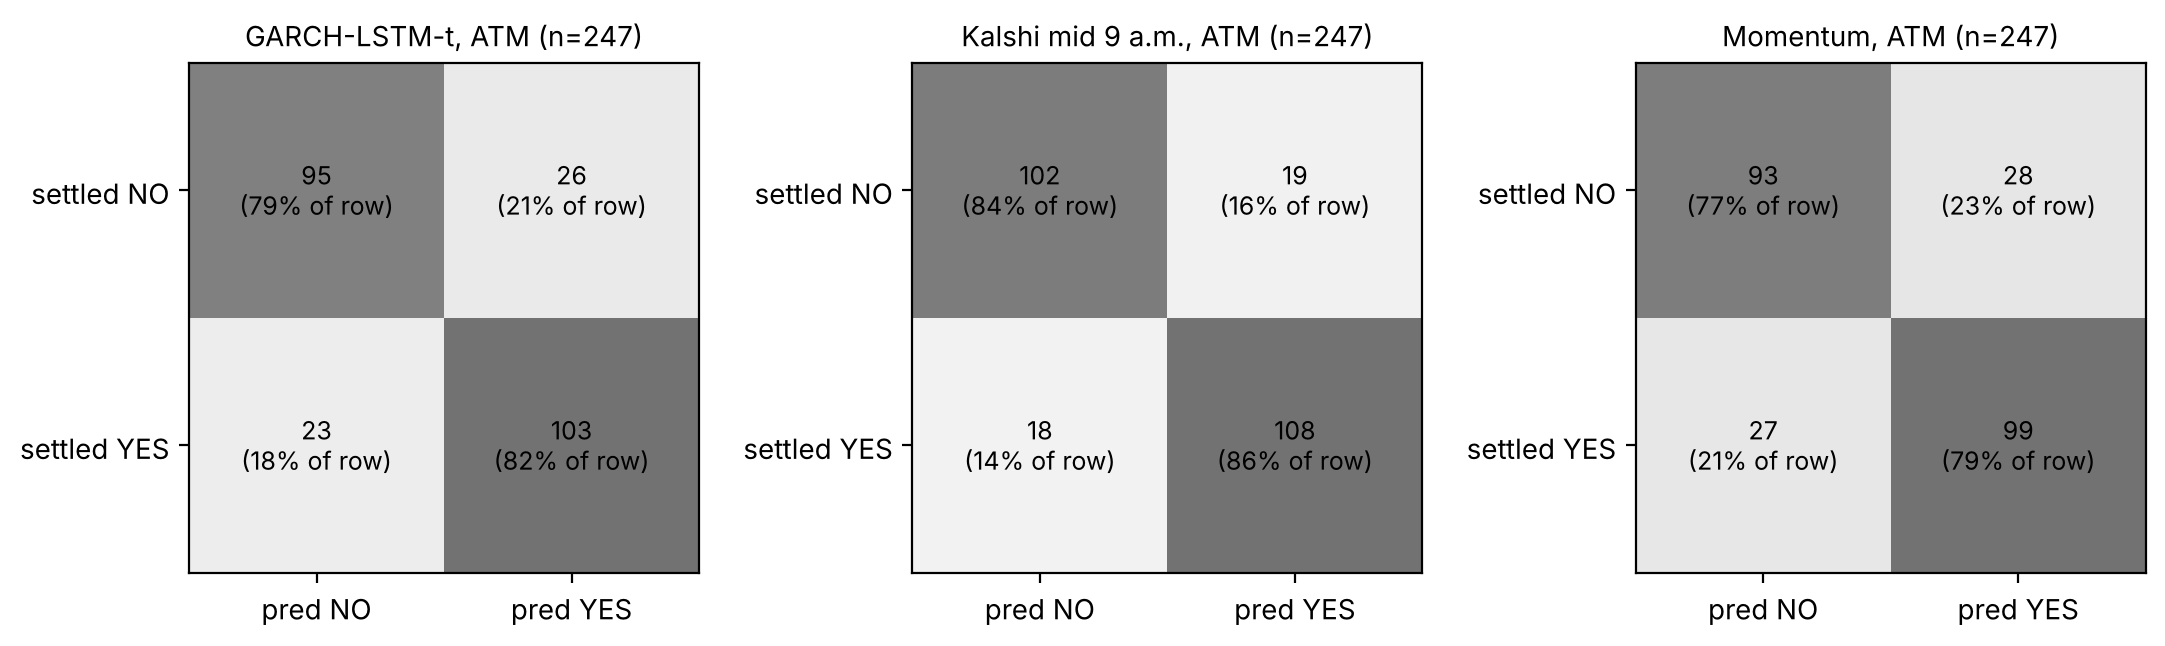

ATM errors of the model: 23 missed YES (price ended above the strike, model said NO; 17 of them on days AAA rose) vs 26 false YES. Recall YES 0.82 vs recall NO 0.79.


,threshold,window,accuracy,balanced_acc,macro_f1,recall_yes,recall_no
0,0.500,fit Aug 20 - Sep 19,0.904,0.909,0.903,0.883,0.934
1,0.500,scored Sep 20 - Oct 19,0.927,0.928,0.926,0.932,0.923
2,0.575,fit Aug 20 - Sep 19,0.913,0.919,0.912,0.880,0.959
3,0.575,scored Sep 20 - Oct 19,0.933,0.932,0.931,0.928,0.936


Threshold chosen on the first half: 0.575; on the later half macro-F1 0.926 at 0.5 vs 0.931 at 0.575.


In [16]:
# 5.6b  Contract-level classification diagnostics: confusion matrix, precision, recall, F1 and balanced accuracy,
# overall and by distance from yesterday's price. Accuracy alone hides two problems:
#   (1) class imbalance: most listed strikes are far from the price, so their outcome is nearly certain;
#   (2) a trivial "no-change" rule (YES iff yesterday's AAA is already above the strike) gets those right for free.
# Signals on the same test contracts (Aug 20 - Oct 19, only contracts with a 9 a.m. book):
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, balanced_accuracy_score
TEW = ds_f["df"].loc[X.TE[0]:X.TE[1]].index
c_te = ds_f["contracts"][ds_f["contracts"].date.isin(TEW)]
cl = E.price_ladder(c_te, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]])
cl = cl.dropna(subset=["bid", "ask", "y"]).copy()
cl["p_mkt"] = ((cl.bid + cl.ask) / 2).clip(.005, .995)
cl = cl.merge(E.price_ladder(c_te, ds_f["res"]["Momentum"].loc[X.TE[0]:X.TE[1]])[["ticker", "p"]].rename(columns={"p": "p_mom"}), on="ticker")
cl["p_nochg"] = np.where(cl.prev > cl.strike, 1.0, 0.0)
cl["dist_c"] = (cl.strike - cl.prev).abs() * 100
cl["band"] = pd.cut(cl.dist_c, [-.01, 1, 2, 100], labels=["ATM (<=1c)", "near (1-2c)", "far (>2c)"])
SIGS = {"GARCH-LSTM-t": "p", "Kalshi mid 9 a.m.": "p_mkt", "Momentum": "p_mom", "No-change rule": "p_nochg"}

def cls_metrics(y, p, thr=.5):
    y = np.asarray(y).astype(int); yh = (np.asarray(p) > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    pr, rc, f1, _ = precision_recall_fscore_support(y, yh, labels=[0, 1], zero_division=0)
    return dict(n=len(y), yes_share=y.mean(), accuracy=(tp + tn) / len(y),
                balanced_acc=balanced_accuracy_score(y, yh) if 0 < y.sum() < len(y) else np.nan,
                precision_yes=pr[1], recall_yes=rc[1], f1_yes=f1[1], precision_no=pr[0], recall_no=rc[0], f1_no=f1[0],
                macro_f1=f1.mean(), TP=tp, FP=fp, FN=fn, TN=tn)

rows = []
for sub, g in [("all", cl)] + [(b, cl[cl.band == b]) for b in cl.band.cat.categories]:
    for nm, col in SIGS.items():
        rows.append(dict(contracts=sub, signal=nm, **cls_metrics(g.y, g[col])))
cls_tab = pd.DataFrame(rows)
print(f"Class balance: {cl.y.mean():.1%} of {len(cl)} test contracts settled YES; "
      + ", ".join(f"{b}: {len(g)} contracts, {g.y.mean():.0%} YES" for b, g in cl.groupby("band", observed=True)))
display(cls_tab.set_index(["contracts", "signal"])[["n", "yes_share", "accuracy", "balanced_acc", "precision_yes", "recall_yes",
                                                     "f1_yes", "recall_no", "f1_no", "macro_f1", "TP", "FP", "FN", "TN"]].round(3))

# Day-block bootstrap (all strikes of a day settle on one number) for the ATM macro-F1 gaps
def day_boot(g, f, n=2000, seed=0):
    days = g.date.unique(); by = {d_: x for d_, x in g.groupby("date")}; rng = np.random.default_rng(seed)
    v = [f(pd.concat([by[d_] for d_ in rng.choice(days, len(days))])) for _ in range(n)]
    return f(g), *np.nanpercentile(v, [2.5, 97.5])
atm = cl[cl.band == "ATM (<=1c)"]
mf1 = lambda col: (lambda g: cls_metrics(g.y, g[col])["macro_f1"])
boot_rows = []
for other in ["p_mkt", "p_mom", "p_nochg"]:
    est, lo, hi = day_boot(atm, lambda g, o=other: mf1("p")(g) - mf1(o)(g))
    boot_rows.append(dict(comparison=f"GARCH-LSTM-t minus {[k for k, v in SIGS.items() if v == other][0]}", ATM_macroF1_diff=est, ci95_low=lo, ci95_high=hi))
boot_cls = pd.DataFrame(boot_rows); display(boot_cls.round(3))

# Confusion matrices at the money, where the decision is genuinely uncertain
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
for a, (nm, col) in zip(ax, [("GARCH-LSTM-t", "p"), ("Kalshi mid 9 a.m.", "p_mkt"), ("Momentum", "p_mom")]):
    cm = confusion_matrix(atm.y.astype(int), (atm[col] > .5).astype(int), labels=[0, 1])
    a.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 1.6)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%} of row)", ha="center", va="center", fontsize=9)
    a.set_xticks([0, 1], ["pred NO", "pred YES"]); a.set_yticks([0, 1], ["settled NO", "settled YES"]); a.set_title(f"{nm}, ATM (n={len(atm)})", fontsize=10)
fig.tight_layout(); plt.show()

# Which kind of error dominates at the money, and on which days?
a_m = atm.assign(pred=(atm.p > .5).astype(int), up=(atm.date.map(ds_f["df"].y) > 0))
fn_, fp_ = int(((a_m.y == 1) & (a_m.pred == 0)).sum()), int(((a_m.y == 0) & (a_m.pred == 1)).sum())
fn_up = ((a_m.y == 1) & (a_m.pred == 0) & a_m.up).sum()
atm_row = cls_tab[(cls_tab.contracts == "ATM (<=1c)") & (cls_tab.signal == "GARCH-LSTM-t")].iloc[0]
print(f"ATM errors of the model: {fn_} missed YES (price ended above the strike, model said NO; {fn_up} of them on days AAA rose) vs "
      f"{fp_} false YES. Recall YES {atm_row.recall_yes:.2f} vs recall NO {atm_row.recall_no:.2f}.")

# Threshold sensitivity (class imbalance): choose the cut-off on the first half of the test window, apply it to the second half
cut = "2026-09-19"; fit_h, tst_h = cl[cl.date <= cut], cl[cl.date > cut]
grid = np.round(np.arange(.30, .71, .025), 3)
best_thr = grid[int(np.argmax([cls_metrics(fit_h.y, fit_h.p, t)["macro_f1"] for t in grid]))]
thr_tab = pd.DataFrame([dict(threshold=t, window=wn, **{k: cls_metrics(g.y, g.p, t)[k] for k in ["accuracy", "balanced_acc", "macro_f1", "recall_yes", "recall_no"]})
                        for t in sorted({.5, best_thr}) for wn, g in [("fit Aug 20 - Sep 19", fit_h), ("scored Sep 20 - Oct 19", tst_h)]])
display(thr_tab.round(3))
t5 = thr_tab[(thr_tab.threshold == .5) & thr_tab.window.str.startswith("scored")].iloc[0]
tb = thr_tab[(thr_tab.threshold == best_thr) & thr_tab.window.str.startswith("scored")].iloc[0]
print(f"Threshold chosen on the first half: {best_thr:.3f}; on the later half macro-F1 {t5.macro_f1:.3f} at 0.5 vs {tb.macro_f1:.3f} at {best_thr:.3f}.")

m_all = cls_tab.set_index(["contracts", "signal"])
FINDINGS.append(dict(diagnostic="class imbalance / no-change baseline",
                     evidence=f"accuracy all strikes: model {m_all.loc[('all', 'GARCH-LSTM-t'), 'accuracy']:.3f}, no-change rule {m_all.loc[('all', 'No-change rule'), 'accuracy']:.3f}; "
                              f"ATM macro-F1 model {m_all.loc[('ATM (<=1c)', 'GARCH-LSTM-t'), 'macro_f1']:.3f}, market {m_all.loc[('ATM (<=1c)', 'Kalshi mid 9 a.m.'), 'macro_f1']:.3f}",
                     verdict="headline accuracy mostly free; ATM is where skill is measured"))
FINDINGS.append(dict(diagnostic="ATM error type", evidence=f"{fn_} missed YES vs {fp_} false YES",
                     verdict="misses up-moves (downward bias)" if fn_ > 1.5 * fp_ else "misses down-moves (upward bias)" if fp_ > 1.5 * fn_ else "balanced errors"))
FINDINGS.append(dict(diagnostic="decision threshold", evidence=f"best on fit half {best_thr:.3f}; later half macro-F1 {t5.macro_f1:.3f} (0.5) vs {tb.macro_f1:.3f}",
                     verdict="keep 0.5" if tb.macro_f1 <= t5.macro_f1 + .01 else "threshold shift helps out of sample"))

**Reading (5.6b).** The YES/NO classes are balanced (51.0% of the 1,105 test contracts settled YES, and 50–53% in every distance band), because Kalshi centres each ladder on the previous price. The real imbalance is in *difficulty*: 615 of 1,105 contracts (56%) are more than 2 cents from yesterday's price, and there the trivial **no-change rule** (YES if and only if yesterday's AAA is already above the strike) is right 94.3% of the time. Over all contracts that rule reaches 0.872 accuracy, against 0.886 for the model and 0.933 for the market. So most of the model's headline accuracy is free; the useful comparison is at the money (247 contracts within 1 cent), where the no-change rule falls to 0.692, the model reaches 0.741 and the market 0.850. Precision and recall per class show which way the model errs there, and the confusion matrices show it directly. The day-block intervals say whether the model's ATM macro-F1 is really below the market and really above momentum and the no-change rule. **[Fill in from the bootstrap table and the "ATM errors" line.]**

The threshold check asks whether the class balance or a probability bias would justify a cut-off other than 0.5. It is chosen on Aug 20 – Sep 19 only.

*Effect on next decisions.* From now on we report accuracy and macro-F1 **by distance band** and always next to the no-change rule, and we select daily models on ATM log loss/Brier rather than all-strike accuracy. If one error type dominates at the money (for example many "false YES"), that is a bias in the forecast mean, and it is fixed in the model (regime/direction input), not by moving the threshold, unless the threshold check shows an out-of-sample gain.

,daily test residuals
days,61.000
mean error (cents),0.117
bias p-value,0.477
MAE (cents),0.722
RMSE (cents),1.269
"corr(pred, actual)",0.743
Ljung-Box Q(7) residuals p,0.335
Ljung-Box Q(7) squared residuals p,0.993
cov50 (nominal 50%),0.475
cov80 (nominal 80%),0.705


Note: the test days are not all consecutive (a few AAA values are missing), so the autocorrelations are approximate.


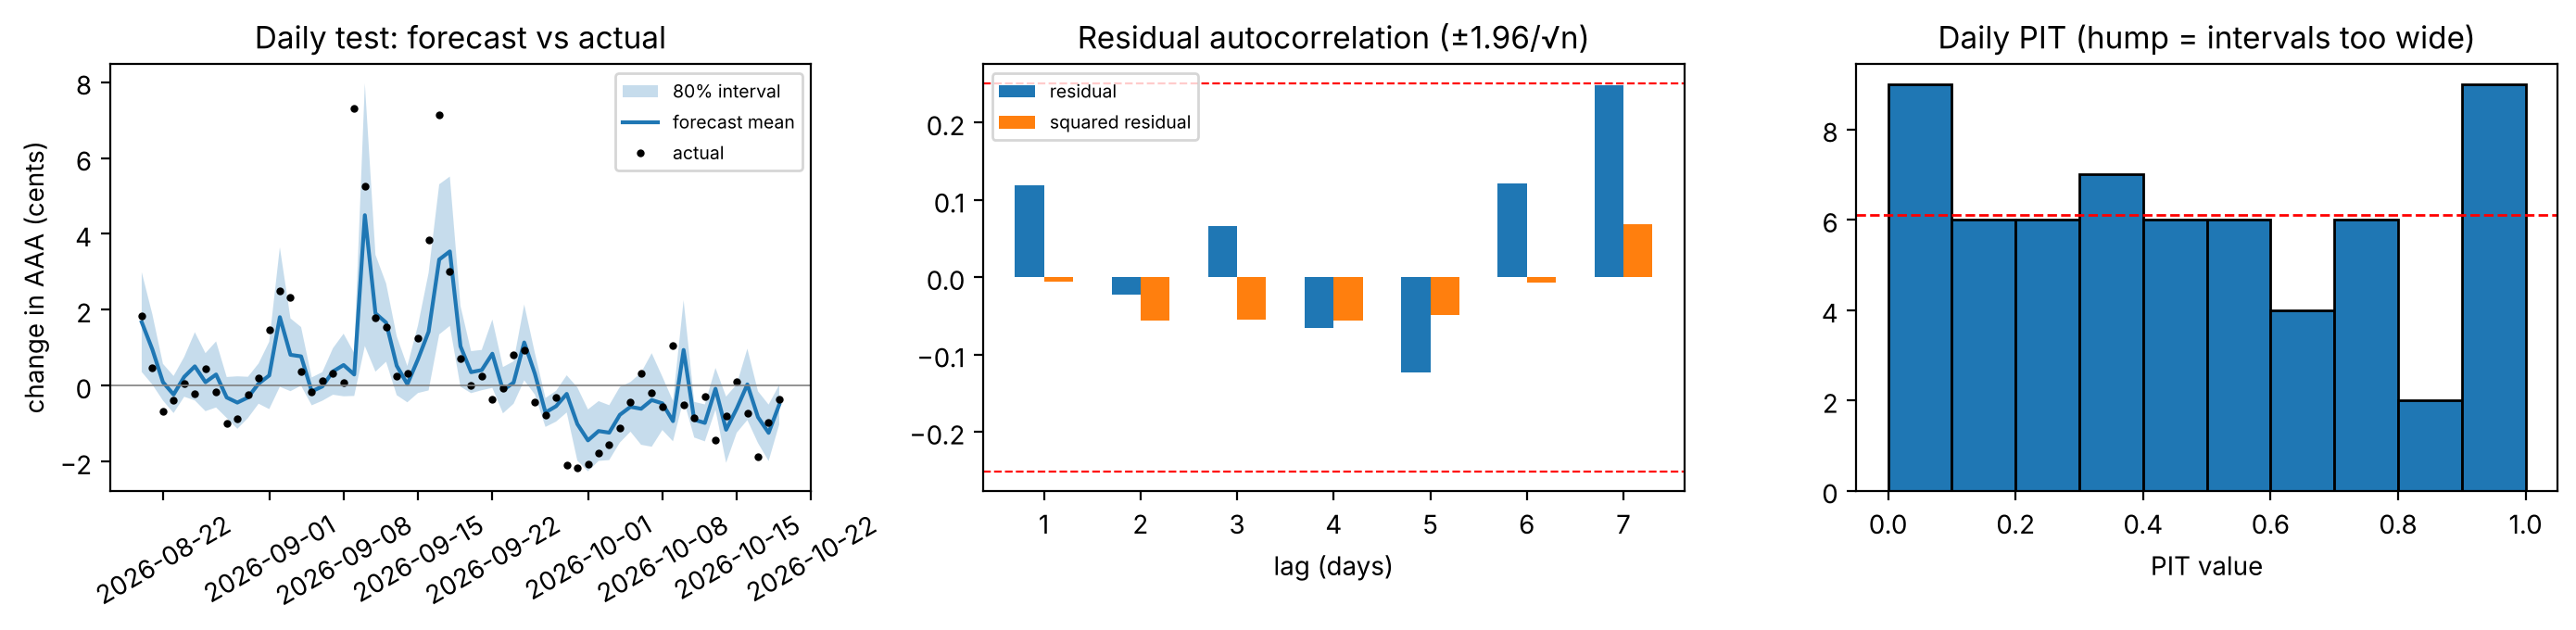

days  MAE_c  bias_c  cov80  dir_acc  contract_err_model  contract_err_market
grouping                 group                                                                                        
realised direction       AAA down           31  0.548  -0.407  0.677    0.774               0.069                0.054
                         AAA up             28  0.947   0.724  0.714    0.857               0.105                0.084
                         flat (<0.05c)       2  0.263  -0.263  1.000    1.000               0.029                0.000
size of move             large >1.5c        16  1.417   0.626  0.562    1.000               0.137                0.088
                         medium 0.5-1.5c    17  0.599   0.007  0.647    0.824               0.070                0.060
                         small <=0.5c       28  0.399  -0.108  0.821    0.714               0.059                0.057
wholesale 2 days earlier falling or flat    38  0.762   0.160  0.658    0.816               0.095                0.057
                         rising             23  0.655   0.045  0.783    0.826               0.071                0.082
weekday of settlement    Fri                 9  0.637  -0.195  0.778    0.778               0.069                0.098
                         Mon                 9  0.224   0.134  0.889    1.000               0.059                0.033
                         Sat                 9  0.577  -0.577  0.556    0.667               0.065                0.065
                         Sun                 9  0.190  -0.067  1.000    0.889               0.025                0.025
                         Thu                 9  0.984   0.722  0.556    0.778               0.092                0.075
                         Tue                 8  1.039  -0.369  0.500    0.625               0.118                0.110
                         Wed                 8  1.525   1.240  0.625    1.000               0.178                0.066

Failure concentration: the worst 7 of 61 days (11%) hold 41% of the model's 94 wrong contracts; 13 days have no wrong contract.


,actual_c,pred_c,lo80_c,hi80_c,pit,d_gulf,strikes,wrong_model,wrong_mkt,outside_80
2026-09-09,7.31,0.298,-0.267,0.863,1.000,0.000,27,14,2,True
2026-09-17,7.14,3.326,1.353,5.308,0.973,0.032,27,7,7,True
2026-09-16,3.83,1.424,-0.121,2.975,0.957,0.009,23,5,1,True
2026-10-09,1.06,-0.930,-1.462,-0.398,0.999,-0.017,17,4,3,True
2026-09-03,2.33,0.816,-0.141,1.776,0.962,-0.115,17,3,0,True
2026-09-29,-2.10,-0.213,-0.702,0.277,0.002,0.000,17,3,2,True


In [17]:
# 5.6c  Residual and failure analysis of the final daily model on the 61 test settlement days.
# Residual = realised AAA change minus forecast mean, in cents. A well-specified model has (i) zero mean residual,
# (ii) no autocorrelation left in the residuals or their squares, (iii) PIT values uniform with nominal interval
# coverage, and (iv) errors that are not concentrated in one kind of day.
from scipy import stats as st
dm = ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]].dropna()
rr = ds_f["df"].loc[dm.index]; rr = rr[rr.y.notna()]; dm = dm.loc[rr.index]
yp = rr.y.values * 100
q = lambda pr: dm.mu.values + dm.scale.values * np.where(np.isinf(dm.df.values), st.norm.ppf(pr), st.t.ppf(pr, np.where(np.isinf(dm.df.values), 30, dm.df.values)))
to_c = lambda pct: rr.aaa_prev.values * (np.exp(pct / 100) - 1) * 100          # percent log change -> cents
res = pd.DataFrame({"actual_c": to_c(yp), "pred_c": to_c(dm.mu.values), "lo80_c": to_c(q(.1)), "hi80_c": to_c(q(.9)),
                    "pit": E.cdf(yp, dm.mu.values, dm.scale.values, dm.df.values), "d_gulf": rr.d_gulf.values}, index=rr.index)
res["err_c"] = res.actual_c - res.pred_c

def acf(x, k):
    x = np.asarray(x) - np.mean(x); d = np.sum(x ** 2)
    return np.array([np.sum(x[j:] * x[:-j]) / d for j in range(1, k + 1)])
def ljung_box(x, k):
    n = len(x); r = acf(x, k); Q = n * (n + 2) * np.sum(r ** 2 / (n - np.arange(1, k + 1))); return Q, st.chi2.sf(Q, k)
K = 7; Q1, p1 = ljung_box(res.err_c, K); Q2, p2 = ljung_box(res.err_c ** 2, K)
bias_p = st.ttest_1samp(res.err_c, 0).pvalue
cov = {f"cov{int(l * 100)}": float(np.mean(np.abs(res.pit - .5) <= l / 2)) for l in (.5, .8, .95)}
resid_tab = pd.Series({"days": len(res), "mean error (cents)": res.err_c.mean(), "bias p-value": bias_p,
                       "MAE (cents)": res.err_c.abs().mean(), "RMSE (cents)": np.sqrt((res.err_c ** 2).mean()),
                       "corr(pred, actual)": np.corrcoef(res.pred_c, res.actual_c)[0, 1],
                       f"Ljung-Box Q({K}) residuals p": p1, f"Ljung-Box Q({K}) squared residuals p": p2,
                       **{f"{k} (nominal {k[3:]}%)": v for k, v in cov.items()},
                       "mean 80% interval width (cents)": (res.hi80_c - res.lo80_c).mean(),
                       "KS test of PIT uniformity p": st.kstest(res.pit, "uniform").pvalue}, name="daily test residuals")
display(resid_tab.to_frame().round(3))
print("Note: the test days are not all consecutive (a few AAA values are missing), so the autocorrelations are approximate.")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].fill_between(res.index, res.lo80_c, res.hi80_c, alpha=.25, label="80% interval"); ax[0].plot(res.index, res.pred_c, label="forecast mean")
ax[0].plot(res.index, res.actual_c, "k.", ms=4, label="actual"); ax[0].axhline(0, c="gray", lw=.6)
ax[0].set_ylabel("change in AAA (cents)"); ax[0].set_title("Daily test: forecast vs actual"); ax[0].legend(fontsize=7); ax[0].tick_params(axis="x", rotation=30)
for lab, x, off in [("residual", res.err_c, -.15), ("squared residual", res.err_c ** 2, .15)]:
    ax[1].bar(np.arange(1, K + 1) + off, acf(x, K), width=.3, label=lab)
ax[1].axhline(1.96 / np.sqrt(len(res)), c="r", ls="--", lw=.8); ax[1].axhline(-1.96 / np.sqrt(len(res)), c="r", ls="--", lw=.8)
ax[1].set_xlabel("lag (days)"); ax[1].set_title("Residual autocorrelation (±1.96/√n)"); ax[1].legend(fontsize=7)
ax[2].hist(res.pit, bins=10, range=(0, 1), edgecolor="k"); ax[2].axhline(len(res) / 10, c="r", ls="--", lw=1)
ax[2].set_xlabel("PIT value"); ax[2].set_title("Daily PIT (hump = intervals too wide)"); fig.tight_layout(); plt.show()

# Uneven performance: where are the errors? Contract errors are joined from 5.6b (same test contracts).
wrong = cl.assign(wrong_model=((cl.p > .5) != (cl.y == 1)), wrong_mkt=((cl.p_mkt > .5) != (cl.y == 1))).groupby("date").agg(
    strikes=("y", "size"), wrong_model=("wrong_model", "sum"), wrong_mkt=("wrong_mkt", "sum"))
res = res.join(wrong, how="left")
mv = res.actual_c.abs()
groups = {"realised direction": np.select([res.actual_c > .05, res.actual_c < -.05], ["AAA up", "AAA down"], "flat (<0.05c)"),
          "size of move": pd.cut(mv, [-.01, .5, 1.5, 100], labels=["small <=0.5c", "medium 0.5-1.5c", "large >1.5c"]).astype(str),
          "wholesale 2 days earlier": np.where(res.d_gulf > 0, "rising", "falling or flat"),
          "weekday of settlement": res.index.day_name().str[:3]}
ug = []
for gname, lab in groups.items():
    for v, g in res.groupby(np.asarray(lab)):
        ug.append(dict(grouping=gname, group=v, days=len(g), MAE_c=g.err_c.abs().mean(), bias_c=g.err_c.mean(),
                       cov80=np.mean(np.abs(g.pit - .5) <= .4), dir_acc=np.mean(np.sign(g.pred_c) == np.sign(g.actual_c)) if (g.actual_c != 0).any() else np.nan,
                       contract_err_model=g.wrong_model.sum() / g.strikes.sum(), contract_err_market=g.wrong_mkt.sum() / g.strikes.sum()))
uneven = pd.DataFrame(ug); display(uneven.set_index(["grouping", "group"]).round(3))

# Failure concentration and the worst days (qualitative output analysis)
wm = res.wrong_model.fillna(0).sort_values(ascending=False)
top10 = max(1, int(np.ceil(.1 * len(wm)))); share = wm.iloc[:top10].sum() / max(wm.sum(), 1)
print(f"Failure concentration: the worst {top10} of {len(wm)} days ({top10 / len(wm):.0%}) hold {share:.0%} of the model's {int(wm.sum())} wrong contracts; "
      f"{int((wm == 0).sum())} days have no wrong contract.")
worst = res.loc[wm.index[:6], ["actual_c", "pred_c", "lo80_c", "hi80_c", "pit", "d_gulf", "strikes", "wrong_model", "wrong_mkt"]]
worst["outside_80"] = (worst.actual_c < worst.lo80_c) | (worst.actual_c > worst.hi80_c)
display(worst.round(3))
up_err = uneven.query("grouping == 'realised direction' and group == 'AAA up'"); dn_err = uneven.query("grouping == 'realised direction' and group == 'AAA down'")
FINDINGS.append(dict(diagnostic="daily residuals", evidence=f"bias {res.err_c.mean():+.2f}c (p={bias_p:.2f}); LB p {p1:.2f} / sq {p2:.2f}; cov50/80/95 {cov['cov50']:.2f}/{cov['cov80']:.2f}/{cov['cov95']:.2f}",
                     verdict=("intervals too wide (under-confident)" if cov["cov80"] > .88 else "intervals too narrow (over-confident)" if cov["cov80"] < .72 else "coverage near nominal")
                             + ("; leftover autocorrelation" if min(p1, p2) < .05 else "; no leftover autocorrelation")))
if len(up_err) and len(dn_err):
    FINDINGS.append(dict(diagnostic="uneven errors by direction", evidence=f"contract error rate up days {up_err.contract_err_model.iloc[0]:.3f} vs down days {dn_err.contract_err_model.iloc[0]:.3f}; bias up {up_err.bias_c.iloc[0]:+.2f}c, down {dn_err.bias_c.iloc[0]:+.2f}c",
                         verdict="worse on rising days" if up_err.contract_err_model.iloc[0] > 1.25 * dn_err.contract_err_model.iloc[0] else
                                 "worse on falling days" if dn_err.contract_err_model.iloc[0] > 1.25 * up_err.contract_err_model.iloc[0] else "similar"))
FINDINGS.append(dict(diagnostic="failure concentration", evidence=f"worst {top10} days hold {share:.0%} of wrong contracts", verdict="concentrated" if share > .4 else "spread out"))

**Reading (5.6c).** The residual table checks the four properties a well-specified forecast should have. Two results are known before running from Part 2 (Revision 3) and the reliability plot above: the Stage 1 daily three-seed ensemble covered 0.93 of test days with its 80% interval (the final model differs only in its weekly input), and the model is under-confident above p = 0.6. So the PIT histogram is expected to be hump-shaped (too few values near 0 and 1) and coverage at 50% and 80% too high: **the daily intervals are too wide**, the opposite of the weekly model's problem (80% coverage 0.73). Ljung–Box on the residuals tests whether a predictable component is left in the mean; on the squared residuals, whether volatility clustering is left after the GARCH input.

The breakdown by kind of day is the failure analysis. The largest moves of the test window are clustered: +7.3 cents on Sep 9 and a run of +3.8, +7.1 and +3.0 cents on Sep 16–18, so if the worst-day table is dominated by those dates the model's failures are price spikes it did not anticipate, which ties back to the 32% up-day share in training (5.6a) and to the weekly model's excess of upper-tail PIT values (Revision 1). The weekday rows have only 8–9 days each and are descriptive only. **[Fill in bias, coverage and Ljung–Box values from the table, and the failure-concentration line.]**

*Effect on next decisions.* Too-wide daily intervals cost Brier on near-the-money strikes even when the side is right; a scale factor fitted on the validation window (Part 2, Revision 1 method) is the cheap fix to test first. A residual bias on rising days supports adding the rising/falling wholesale regime input already in the Stage 3 plan. Leftover autocorrelation would justify a longer lookback; none would argue against it.

In [18]:
# 5.6d  Stability: do the three seeds of the final daily model agree on the CONTRACT decisions?
# Part 2 (Revision 5) showed the seed spread of daily NLL. Here the question is whether a different seed would have
# bought a different side of the same contract, which matters more for a strike ladder than the NLL spread.
runs_f = ds_f["runs"][7]["t"]
seed_p, seed_rows = {}, []
for sd, r in enumerate(runs_f):
    d_ = r["dist"].loc[X.TE[0]:X.TE[1]].dropna()
    pr = E.price_ladder(c_te, d_).set_index("ticker").p.reindex(cl.ticker)
    seed_p[sd] = pr.values
    yy = ds_f["df"].y.loc[d_.index]; ok = yy.notna()
    seed_rows.append(dict(member=f"seed {sd}", **E.dist_metrics(yy[ok].values * 100, d_[ok.values]),
                          **{k: v for k, v in cls_metrics(cl.y, pr.values).items() if k in ("accuracy", "balanced_acc", "macro_f1")},
                          ATM_accuracy=cls_metrics(cl.y[cl.band == "ATM (<=1c)"], pr.values[(cl.band == "ATM (<=1c)").values])["accuracy"],
                          brier=float(np.mean((pr.values - cl.y.values) ** 2))))
ens_m = E.dist_metrics(ds_f["df"].y.loc[dm.index].values * 100, dm)
seed_rows.append(dict(member="3-seed ensemble", **ens_m, **{k: v for k, v in cls_metrics(cl.y, cl.p).items() if k in ("accuracy", "balanced_acc", "macro_f1")},
                      ATM_accuracy=cls_metrics(atm.y, atm.p)["accuracy"], brier=float(np.mean((cl.p - cl.y) ** 2))))
seed_tab = pd.DataFrame(seed_rows).set_index("member")[["NLL", "CRPS", "MAE", "cov80", "accuracy", "ATM_accuracy", "balanced_acc", "macro_f1", "brier"]]
display(seed_tab.round(4))

P_ = np.column_stack([seed_p[s] for s in seed_p]); side = P_ > .5
cl["seed_disagree"] = side.any(1) & ~side.all(1); cl["seed_sd_p"] = P_.std(1)
stab = cl.groupby("band", observed=True).agg(contracts=("y", "size"), seeds_disagree_on_side=("seed_disagree", "mean"),
                                             mean_sd_of_p=("seed_sd_p", "mean"), max_sd_of_p=("seed_sd_p", "max"))
display(stab.round(3))
dis = cl[cl.seed_disagree]
acc_dis = ((dis.p > .5) == (dis.y == 1)).mean() if len(dis) else np.nan
acc_mkt_dis = ((dis.p_mkt > .5) == (dis.y == 1)).mean() if len(dis) else np.nan
mu_corr = np.corrcoef(np.column_stack([r["dist"].loc[dm.index].mu.values for r in runs_f]).T)
print(f"Seeds disagree on the side of {cl.seed_disagree.mean():.1%} of test contracts ({int(cl.seed_disagree.sum())}); on those the ensemble is right "
      f"{acc_dis:.0%} of the time and the market {acc_mkt_dis:.0%}. Correlation of the seeds' daily mean forecasts: "
      f"{mu_corr[np.triu_indices(len(runs_f), 1)].min():.2f} to {mu_corr[np.triu_indices(len(runs_f), 1)].max():.2f}. "
      f"Seed range of ATM accuracy: {seed_tab.ATM_accuracy.iloc[:-1].min():.3f} to {seed_tab.ATM_accuracy.iloc[:-1].max():.3f}.")
FINDINGS.append(dict(diagnostic="seed stability (contracts)",
                     evidence=f"seeds disagree on {cl.seed_disagree.mean():.1%} of contracts ({stab.seeds_disagree_on_side.get('ATM (<=1c)', np.nan):.0%} of ATM); ATM accuracy by seed {seed_tab.ATM_accuracy.iloc[:-1].min():.2f}-{seed_tab.ATM_accuracy.iloc[:-1].max():.2f}",
                     verdict="unstable at the money" if stab.seeds_disagree_on_side.get("ATM (<=1c)", 0) > .1 else "stable")) 

,NLL,CRPS,MAE,cov80,accuracy,ATM_accuracy,balanced_acc,macro_f1,brier
member,,,,,,,,,
seed 0,-0.1469,0.1324,0.1719,0.6885,0.9176,0.8219,0.9179,0.9176,0.0644
seed 1,-0.0761,0.1329,0.1667,0.6885,0.9195,0.8138,0.9197,0.9195,0.0641
seed 2,-0.0778,0.1330,0.1716,0.7049,0.9104,0.7895,0.9105,0.9104,0.0641
3-seed ensemble,-0.1343,0.1314,0.1680,0.7049,0.9149,0.8016,0.9152,0.9149,0.0631


,contracts,seeds_disagree_on_side,mean_sd_of_p,max_sd_of_p
band,,,,
ATM (<=1c),247,0.081,0.036,0.200
near (1-2c),243,0.045,0.018,0.168
far (>2c),615,0.013,0.007,0.184


Seeds disagree on the side of 3.5% of test contracts (39); on those the ensemble is right 51% of the time and the market 62%. Correlation of the seeds' daily mean forecasts: 0.96 to 0.98. Seed range of ATM accuracy: 0.789 to 0.822.


**Reading (5.6d).** Part 2 showed that the daily NLL depends on the seed (seeds 0–2 were a favourable draw). This table measures what that means for decisions: the share of contracts where the three seeds would buy different sides, by distance band, and how the ensemble and the market do on exactly those contracts. Disagreement should be near zero far from the price and concentrated at the money, where it directly limits ATM accuracy. **[Fill in from the printed stability line.]**

*Effect on next decisions.* If seeds disagree on a meaningful share of ATM contracts, the daily model should keep at least five seeds (Part 2, Revision 5), and contracts where the seeds disagree should be treated as "no signal" in any trading rule rather than traded.

In [19]:
# 5.6e  Summary of the diagnostics (every line is computed above; the verdicts follow the stated rules)
diag_summary = pd.DataFrame(FINDINGS)
with pd.option_context("display.max_colwidth", 140): display(diag_summary)

,diagnostic,evidence,verdict
0,weekly train/val/test gap,"NLL 1.66/1.68/2.01; skill vs ECM -0.23 train, -0.33 test; cov80 test 0.74",GENERALIZES
1,daily train/val/test gap,"NLL -0.69/-0.17/-0.13; skill vs ECM -0.50 train, -0.73 test; cov80 test 0.70",GENERALIZES
2,daily convergence,best epoch 15-41; val NLL rises 0.22 after it,overfits after the best epoch (early stopping is doing the regularizing)
3,class imbalance / no-change baseline,"accuracy all strikes: model 0.915, no-change rule 0.872; ATM macro-F1 model 0.801, market 0.850",headline accuracy mostly free; ATM is where skill is measured
4,ATM error type,23 missed YES vs 26 false YES,balanced errors
5,decision threshold,best on fit half 0.575; later half macro-F1 0.926 (0.5) vs 0.931,keep 0.5
6,daily residuals,bias +0.12c (p=0.48); LB p 0.33 / sq 0.99; cov50/80/95 0.48/0.70/0.93,intervals too narrow (over-confident); no leftover autocorrelation
7,uneven errors by direction,"contract error rate up days 0.105 vs down days 0.069; bias up +0.72c, down -0.41c",worse on rising days
8,failure concentration,worst 7 days hold 41% of wrong contracts,concentrated
9,seed stability (contracts),seeds disagree on 3.5% of contracts (8% of ATM); ATM accuracy by seed 0.79-0.82,stable


**What the diagnostics change in the next modeling round.** The table above is regenerated on every run. Read together with the earlier sections, the evidence points to a model that is limited by data and regime, not by capacity or optimization. The daily network learns its useful signal in the first epochs and then overfits on 83 windows (5.6a; Part 2), so a bigger or longer-trained network is not the next step. Its headline accuracy is mostly the easy far-from-price contracts that the no-change rule also gets right (5.6b), so model selection moves to at-the-money metrics. Its errors are not random: daily intervals are too wide while weekly intervals are too narrow (5.6c and Revision 1), and the hardest days are price spikes in a period whose direction mix differs from the training data (5.6a, 5.6c).

| Finding | Next modeling decision |
|---|---|
| Overfitting after a few epochs on 83 windows; seed-dependent results | Keep early stopping and stronger regularization; use ≥5 seeds; add daily labels as Kalshi settles rather than capacity |
| Accuracy dominated by easy strikes; no-change rule close behind | Select and report on ATM Brier/log loss and macro-F1 by distance band, always beside the no-change rule and the market |
| Daily intervals too wide, weekly too narrow | Test a validation-fitted scale factor for the daily model; keep the weekly shape problem (Part 2, Revision 1) on the list |
| Errors concentrated on rising/spike days; training mostly falling prices | Add the rising-versus-falling wholesale regime input (Stage 3 item 3) and fresher wholesale data (item 1) |
| Seeds disagree at the money | Treat seed disagreement as "no trade"; do not optimise a trading rule on 30 days |

**[After running, check that each row matches its verdict in the summary table; drop or reword any row the run does not support.]**

## 6. Challenges and mitigation

| Challenge | Effect | Mitigation |
|---|---|---|
| Weekly EIA labels cannot define daily AAA moves | Original target was not learnable | Daily AAA values from Kalshi `expiration_value` (233 days); the 10-year history is used by a separate weekly model that feeds the daily one |
| Only 83 complete daily training windows | Daily networks overfit within a few epochs | One 16-unit layer, dropout 0.3, L2 1e-3, early stopping, three-seed ensembles, strict chronological splits |
| Weak residual volatility clustering | The GARCH assumption might not hold | ARCH-LM on ECM residuals plus an ablation; GARCH kept only because it improves validation NLL |
| EIA wholesale prices post once a week | Daily features are stale | Manual wholesale CSV in the pipeline; fresher inputs are the first Stage 3 task |
| Market benchmark taken one hour after the open | The market has more information than the model | Stated with every comparison; Stage 3 compares at matched times |
| Fee rounding error found during review | Backtest overstated costs | Fixed to Kalshi's centicent rounding (Kalshi, 2026) |
| Kalshi API rate limits (HTTP 429) | Incomplete historical order books | Retry with backoff; benchmark scored only where a book exists |
| Small evaluation samples | Low-power tests | Event-block bootstrap intervals, seed spread, sample sizes reported |

## 7. Reflection and forward plan

**What mattered most.** The proposal's central problem, learning a daily target from weekly labels, is resolved: Kalshi stores the exact AAA value it settled on, so the daily model trains and is scored on real settlement data and real listed strikes. Three findings shaped the work. First, the biggest gain came from the heavy-tailed Student-t head (weekly test NLL 2.76 to 2.06); the GARCH input added a smaller gain (2.06 to 2.03 weekly, 0.33 to 0.19 daily), even though residual ARCH tests are weak, so it is kept on evidence from the ablation rather than assumption. Second, better probabilistic fit did not translate into better contract decisions: the Kalshi price is significantly more accurate (accuracy difference -4.7 points, 95% CI -7.8 to -2.0), and a fee-aware backtest at 9:00 a.m. loses money. Third, the daily networks overfit within a few epochs on only 83 training windows.

**Limitations.** The daily training sample is very small, wholesale inputs are up to a week stale, the weekly model's 80% intervals under-cover the test period (0.73), errors are larger when wholesale prices rise, Momentum is a strong baseline at the money, and the market benchmark has one extra hour of information. We therefore make no claim of a trading edge.

**Lessons.** Starting with simple baselines was the right call: the Gaussian LSTM lost to the error-correction model, while the Student-t head, the GARCH input and the LSTM on top of the GARCH volatility (daily test NLL 0.41 for GARCH alone vs 0.19) each earned their complexity in an ablation. Controlled one-factor experiments gave gains of about one seed standard deviation, so tuning is a minor lever compared with data. An independent review of this notebook also caught a fee-rounding error, which is why every number here is regenerated from code.

**Stage 3 plan.** (1) Fresher inputs: daily wholesale closes and the latest AAA value, the largest known gap. (2) More daily labels as contracts settle, stronger regularization and a small tuning study for the daily model. (3) A rising-versus-falling wholesale regime input to address the asymmetric errors. (4) Market comparison at matched times, with event-block bootstrap intervals, including whether quotes in the first minutes after the open are less efficient (optional). (5) Only if the core pipeline holds, one optional architecture (Transformer encoder) on identical splits; the neural SDE stays out of scope. Minimum implementation: if daily labels stop, the 10-year weekly model, already scored out of sample on 967 Kalshi weekly contracts (accuracy 0.727), is the fallback deliverable. Team plan: one lead and one reviewer per workstream (data, baselines, deep models, evaluation), a weekly meeting, and the notebook rerun end to end before each milestone.

## Revision log (for the contribution table)

| Date | Who | What |
|---|---|---|
| 2026-10-27 | Yixin Tian | Checked the figures in the text against the data (233 settled daily AAA days, 1,105 priced test contracts on 61 days) and filled in the owner field |
| 2026-10-27 | Yixin Tian | Revision 1: binomial tail, coverage and mean-PIT tests for the weekly forecast, overall and by wholesale regime |
| 2026-10-27 | Yixin Tian | Revision 2: market calibration by price bucket with event-block bootstrap intervals (data only) |
| 2026-10-27 | Yixin Tian | Revision 3: split the blend's gain into market recalibration and the model's own contribution |
| 2026-10-27 | Yixin Tian | Revision 4: day-block bootstrap ROI intervals, YES/NO split and no-skill controls for the 9 a.m. backtest |
| 2026-10-27 | Yixin Tian | Revision 5: out-of-sample check of the published Oct 20 forecast against the Kalshi settlement |
| 2026-11-07 | Yixin Tian | 5.6a: train/validation/test gap and skill vs ECM for the final weekly and daily models, target-shift table, convergence of the final daily runs |
| 2026-11-07 | Yixin Tian | 5.6b: confusion matrices, precision/recall/F1 and balanced accuracy by distance band, no-change baseline, day-block intervals, threshold check |
| 2026-11-07 | Yixin Tian | 5.6c: daily residual analysis (bias, Ljung-Box, coverage), error breakdown by kind of day, worst-day table |
| 2026-11-07 | Yixin Tian | 5.6d-e: contract-level seed stability; diagnostic summary and next modeling decisions |


## Reproducibility

Run this notebook top to bottom (Kernel → Restart & Run All). Tested with Python 3.13, TensorFlow 2.21, pandas,
scikit-learn, statsmodels, arch and scipy (the setup cell prints the versions used). Seeds 0–2 are fixed, and two clean
runs reproduced every number in this notebook. Code is in `gaslab/` (data, models, evaluate, pipeline, experiments,
service); data is in `data/`. In the project repository: `python update_data.py` refreshes the data from FRED and Kalshi;
`python train_model.py` then `python forecast.py` give tomorrow's AAA forecast; new rows can be added in
`data/manual_aaa.csv` (`date,aaa`) and `data/manual_wholesale.csv` (`date,whsl_gulf,whsl_nyh,wti,brent`).

## References

AAA. (2026). *AAA gas prices*. https://gasprices.aaa.com

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Borenstein, S., Cameron, A. C., & Gilbert, R. (1997). Do gasoline prices respond asymmetrically to crude oil price changes? *The Quarterly Journal of Economics, 112*(1), 305–339. https://doi.org/10.1162/003355397555118

Bürgi, C., Deng, W., & Whelan, K. (2026, February 18). The economics of the Kalshi prediction market. *VoxEU*, CEPR. https://cepr.org/voxeu/columns/economics-kalshi-prediction-market

Chesnes, M. (2016). Asymmetric pass-through in U.S. gasoline prices. *The Energy Journal, 37*(1), 153–180. https://doi.org/10.5547/01956574.37.1.mche

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378. https://doi.org/10.1198/016214506000001437

Kalshi. (n.d.). *Kalshi trade API v2* [API documentation]. https://docs.kalshi.com

Kalshi. (2026). *Fee schedule* (effective July 7, 2026). https://kalshi.com/docs/kalshi-fee-schedule.pdf

Kim, H. Y., & Won, C. H. (2018). Forecasting the volatility of stock price index: A hybrid model integrating LSTM with multiple GARCH-type models. *Expert Systems with Applications, 103*, 25–37. https://doi.org/10.1016/j.eswa.2018.03.002

U.S. Energy Information Administration. (2026). *GASREGW, DGASUSGULF, DGASNYH, DCOILBRENTEU, DCOILWTICO* [Data sets]. FRED, Federal Reserve Bank of St. Louis. https://fred.stlouisfed.org

Zhao, P., Zhu, H., Ng, W. S. H., & Lee, D. L. (2024). From GARCH to neural network for volatility forecast. *Proceedings of the AAAI Conference on Artificial Intelligence, 38*(15), 16998–17006. https://doi.org/10.1609/aaai.v38i15.29643